In [ ]:
print("ACKLEY FUNCTION")

ACKLEY FUNCTION


In [ ]:
import numpy as np
import random
import time
from math import exp, sqrt, cos, pi

# Ackley function definition
def ackley(position):
    a = 20
    b = 0.2
    c = 2 * pi
    n = len(position)
    sum1 = sum([x**2 for x in position])
    sum2 = sum([cos(c * x) for x in position])
    term1 = -a * exp(-b * sqrt(sum1 / n))
    term2 = -exp(sum2 / n)
    return term1 + term2 + a + exp(1)

# Particle Swarm Optimization (PSO)
class Particle:
    def __init__(self, dimensions, bounds):
        self.position = np.random.uniform(bounds[:, 0], bounds[:, 1], dimensions)
        self.velocity = np.random.uniform(bounds[:, 0], bounds[:, 1], dimensions)
        self.best_position = self.position.copy()
        self.best_value = ackley(self.position)

    def update_personal_best(self):
        current_value = ackley(self.position)
        if current_value < self.best_value:
            self.best_value = current_value
            self.best_position = self.position.copy()

    def update_velocity(self, global_best_position, inertia_weight=0.7, cognitive_weight=1.5, social_weight=1.5):
        r1, r2 = np.random.rand(), np.random.rand()
        cognitive_component = cognitive_weight * r1 * (self.best_position - self.position)
        social_component = social_weight * r2 * (global_best_position - self.position)
        self.velocity = inertia_weight * self.velocity + cognitive_component + social_component

    def move(self, bounds):
        self.position += self.velocity
        self.position = np.clip(self.position, bounds[:, 0], bounds[:, 1])

def pso_ackley(dimensions, num_particles, max_iterations, bounds):
    particles = [Particle(dimensions, bounds) for _ in range(num_particles)]
    global_best_position = particles[0].best_position.copy()
    global_best_value = ackley(global_best_position)

    for iteration in range(max_iterations):
        for particle in particles:
            particle.update_personal_best()
            if particle.best_value < global_best_value:
                global_best_value = particle.best_value
                global_best_position = particle.best_position.copy()

        for particle in particles:
            particle.update_velocity(global_best_position)
            particle.move(bounds)

    return global_best_position, global_best_value

# Improved Elephant Herding Optimization (EHO)
class Elephant:
    def __init__(self, dimensions, bounds):
        self.position = np.random.uniform(bounds[:, 0], bounds[:, 1], dimensions)
        self.velocity = np.random.uniform(bounds[:, 0], bounds[:, 1], dimensions)
        self.fitness = ackley(self.position)

    def update_position(self, herd_best_position, bounds, iteration, max_iterations):
        r = np.random.rand()
        inertia_weight = 0.9 - 0.5 * (iteration / max_iterations)  # Decreasing inertia weight
        self.velocity = inertia_weight * self.velocity + np.random.rand() * (herd_best_position - self.position)
        new_position = self.position + self.velocity
        self.position = np.clip(new_position, bounds[:, 0], bounds[:, 1])
        self.fitness = ackley(self.position)

    def mutate(self, bounds, mutation_rate):
        if np.random.rand() < mutation_rate:
            mutation_vector = np.random.uniform(bounds[:, 0], bounds[:, 1], len(self.position))
            self.position = np.clip(self.position + mutation_vector, bounds[:, 0], bounds[:, 1])
        self.fitness = ackley(self.position)

def eho_ackley(dimensions, num_elephants, num_herds, max_iterations, bounds):
    elephants = [Elephant(dimensions, bounds) for _ in range(num_elephants)]
    global_best_position = min(elephants, key=lambda e: e.fitness).position
    global_best_fitness = ackley(global_best_position)

    for iteration in range(max_iterations):
        dynamic_herds = int(num_herds - (num_herds - 1) * (iteration / max_iterations))  # Reduce herd size over time
        herds = np.array_split(elephants, dynamic_herds)
        dynamic_mutation_rate = 0.2 * (1 - iteration / max_iterations)  # Decrease mutation rate over time

        for herd in herds:
            herd_best_position = min(herd, key=lambda e: e.fitness).position
            for elephant in herd:
                elephant.update_position(herd_best_position, bounds, iteration, max_iterations)
                elephant.mutate(bounds, dynamic_mutation_rate)

        # Update global best elephant
        current_global_best = min(elephants, key=lambda e: e.fitness)
        if current_global_best.fitness < global_best_fitness:
            global_best_position = current_global_best.position
            global_best_fitness = current_global_best.fitness

    return global_best_position, global_best_fitness

# Genetic Algorithm (GA)
def ga_ackley(dimensions, num_individuals, max_generations, bounds, mutation_prob=0.2):
    def crossover(parent1, parent2):
        point = np.random.randint(1, len(parent1) - 1)
        child1 = np.concatenate((parent1[:point], parent2[point:]))
        child2 = np.concatenate((parent2[:point], parent1[point:]))
        return child1, child2

    def mutate(individual):
        mutation_point = np.random.randint(len(individual))
        individual[mutation_point] = np.random.uniform(bounds[mutation_point, 0], bounds[mutation_point, 1])
        return individual

    population = [np.random.uniform(bounds[:, 0], bounds[:, 1], dimensions) for _ in range(num_individuals)]
    best_individual = min(population, key=lambda ind: ackley(ind))
    best_value = ackley(best_individual)

    for generation in range(max_generations):
        new_population = []
        for i in range(num_individuals // 2):
            parent1, parent2 = random.choices(population, k=2)
            child1, child2 = crossover(parent1, parent2)
            if np.random.rand() < mutation_prob:
                child1 = mutate(child1)
            if np.random.rand() < mutation_prob:
                child2 = mutate(child2)
            new_population.extend([child1, child2])

        population = new_population
        best_candidate = min(population, key=lambda ind: ackley(ind))
        best_candidate_value = ackley(best_candidate)
        if best_candidate_value < best_value:
            best_individual = best_candidate
            best_value = best_candidate_value

    return best_individual, best_value

# Ant Colony Optimization (ACO)
class Ant:
    def __init__(self, bounds):
        self.position = np.random.uniform(bounds[:, 0], bounds[:, 1])
        self.fitness = ackley(self.position)

    def update_position(self, pheromones, bounds, alpha=1.0, beta=1.0):
        for i in range(len(self.position)):
            pheromone_level = pheromones[i][0]  # Ensure we treat pheromone as a scalar
            attraction = pheromone_level ** alpha
            exploration = (1 / (np.abs(bounds[i, 1] - bounds[i, 0]))) ** beta
            perturbation = (attraction - 0.5) * exploration
            self.position[i] += perturbation

            # Ensure the position stays within bounds
            self.position[i] = np.clip(self.position[i], bounds[i, 0], bounds[i, 1])

def aco_ackley(dimensions, num_ants, max_iterations, bounds, evaporation_rate=0.1):
    pheromones = np.ones((len(bounds), 1))  # Initialize pheromones for each parameter (angle, tx, ty)
    ants = [Ant(bounds) for _ in range(num_ants)]
    global_best_position = ants[0].position.copy()
    global_best_value = float('inf')

    for iteration in range(max_iterations):
        # Move ants and evaluate fitness
        for ant in ants:
            ant.update_position(pheromones, bounds)
            fitness = ackley(ant.position)
            if fitness < global_best_value:
                global_best_position = ant.position.copy()
                global_best_value = fitness

        # Update pheromones based on the global best
        for i in range(len(pheromones)):
            pheromones[i] = (1 - evaporation_rate) * pheromones[i] + evaporation_rate * global_best_value

    return global_best_position, global_best_value

# Run the comparison between PSO, EHO, GA, and ACO for the Ackley function
def test_optimization_algorithms_on_ackley():
    dimensions = 10  # Ackley function in 10 dimensions
    num_particles = 50  # for PSO
    num_elephants = 50  # for EHO
    num_herds = 5       # for EHO
    num_individuals = 50  # for GA
    num_ants = 50        # for ACO
    max_iterations = 100  # Maximum iterations/generations
    bounds = np.array([[-32.768, 32.768]] * dimensions)  # Typical bounds for Ackley function

    print("Testing PSO on Ackley Function...")
    start_time = time.time()
    best_position_pso, best_value_pso = pso_ackley(dimensions, num_particles, max_iterations, bounds)
    pso_time = time.time() - start_time
    print(f"PSO Best Value (Ackley): {best_value_pso}, Execution Time: {pso_time:.5f} seconds")

    print("\nTesting Improved EHO on Ackley Function...")
    start_time = time.time()
    best_position_eho, best_value_eho = eho_ackley(dimensions, num_elephants, num_herds, max_iterations, bounds)
    eho_time = time.time() - start_time
    print(f"EHO Best Value (Ackley): {best_value_eho}, Execution Time: {eho_time:.5f} seconds")

    print("\nTesting GA on Ackley Function...")
    start_time = time.time()
    best_position_ga, best_value_ga = ga_ackley(dimensions, num_individuals, max_iterations, bounds)
    ga_time = time.time() - start_time
    print(f"GA Best Value (Ackley): {best_value_ga}, Execution Time: {ga_time:.5f} seconds")

    print("\nTesting ACO on Ackley Function...")
    start_time = time.time()
    best_position_aco, best_value_aco = aco_ackley(dimensions, num_ants, max_iterations, bounds)
    aco_time = time.time() - start_time
    print(f"ACO Best Value (Ackley): {best_value_aco}, Execution Time: {aco_time:.5f} seconds")

    # Show a comparison of results
    print("\nSummary of Results:")
    print(f"PSO: Best Value = {best_value_pso}, Time = {pso_time:.5f} seconds")
    print(f"EHO: Best Value = {best_value_eho}, Time = {eho_time:.5f} seconds")
    print(f"GA:  Best Value = {best_value_ga}, Time = {ga_time:.5f} seconds")
    print(f"ACO: Best Value = {best_value_aco}, Time = {aco_time:.5f} seconds")

# Run the comparison of optimization algorithms on the Ackley function
test_optimization_algorithms_on_ackley()


Testing PSO on Ackley Function...
PSO Best Value (Ackley): 5.09211346966514, Execution Time: 0.11082 seconds

Testing Improved EHO on Ackley Function...
EHO Best Value (Ackley): 4.7997695069642425, Execution Time: 0.21845 seconds

Testing GA on Ackley Function...
GA Best Value (Ackley): 15.811119901981645, Execution Time: 0.09717 seconds

Testing ACO on Ackley Function...
ACO Best Value (Ackley): 19.943817220955953, Execution Time: 0.52352 seconds

Summary of Results:
PSO: Best Value = 5.09211346966514, Time = 0.11082 seconds
EHO: Best Value = 4.7997695069642425, Time = 0.21845 seconds
GA:  Best Value = 15.811119901981645, Time = 0.09717 seconds
ACO: Best Value = 19.943817220955953, Time = 0.52352 seconds


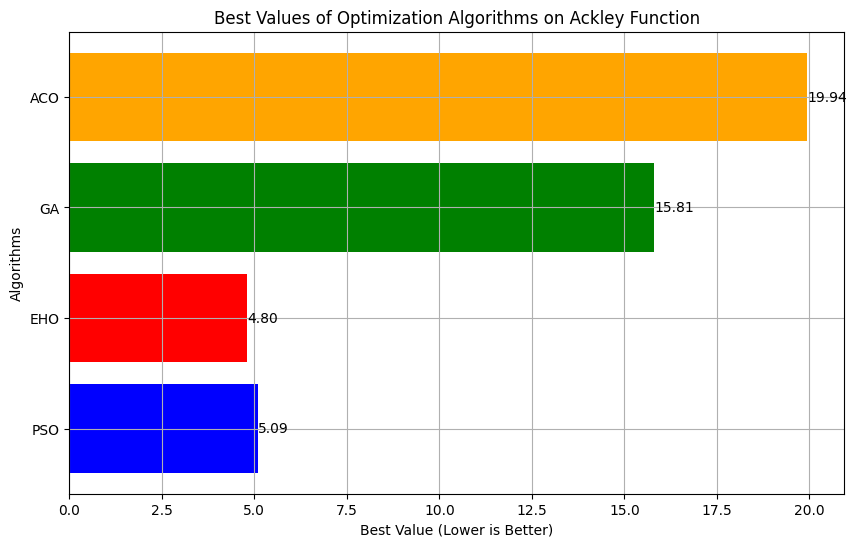

In [ ]:
import matplotlib.pyplot as plt

# Data for the chart
best_values = [5.09211346966514, 4.7997695069642425, 15.811119901981645, 19.943817220955953]  # Best values from your new results
algorithms = ['PSO', 'EHO', 'GA', 'ACO']  # Algorithm names

# Create the horizontal bar plot
plt.figure(figsize=(10, 6))
plt.barh(algorithms, best_values, color=['blue', 'red', 'green', 'orange'])

# Add labels and title
plt.xlabel('Best Value (Lower is Better)')
plt.ylabel('Algorithms')
plt.title('Best Values of Optimization Algorithms on Ackley Function')
plt.grid(True)

# Adding annotations to the bars
for index, value in enumerate(best_values):
    plt.text(value, index, f'{value:.2f}', va='center')

# Show the plot
plt.show()


In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("RASTRIGIN FUNCTION")

RASTRIGIN FUNCTION


In [ ]:
import numpy as np
import random
import time

# Rastrigin function definition
def rastrigin(position):
    n = len(position)
    return 10 * n + sum([(x ** 2 - 10 * np.cos(2 * np.pi * x)) for x in position])

# Particle class for PSO
class Particle:
    def __init__(self, dimensions, bounds):
        self.position = np.random.uniform(bounds[0], bounds[1], dimensions)
        self.velocity = np.random.uniform(bounds[0], bounds[1], dimensions)
        self.best_position = self.position.copy()
        self.best_value = rastrigin(self.position)

    def update_personal_best(self):
        current_value = rastrigin(self.position)
        if current_value < self.best_value:
            self.best_value = current_value
            self.best_position = self.position.copy()

    def update_velocity(self, global_best_position, inertia_weight=0.95, cognitive_weight=0.3, social_weight=0.3):  # Lower weights
        r1, r2 = np.random.rand(), np.random.rand()
        cognitive_component = cognitive_weight * r1 * (self.best_position - self.position)
        social_component = social_weight * r2 * (global_best_position - self.position)
        self.velocity = inertia_weight * self.velocity + cognitive_component + social_component

    def move(self, bounds):
        self.position += self.velocity
        # Ensure that the particle stays within the bounds
        self.position = np.clip(self.position, bounds[0], bounds[1])

def pso_rastrigin(dimensions, num_particles, max_iterations, bounds=(-5.12, 5.12)):
    particles = [Particle(dimensions, bounds) for _ in range(num_particles)]
    global_best_position = particles[0].best_position.copy()
    global_best_value = rastrigin(global_best_position)

    for iteration in range(max_iterations):
        for particle in particles:
            particle.update_personal_best()
            if particle.best_value < global_best_value:
                global_best_value = particle.best_value
                global_best_position = particle.best_position.copy()

        for particle in particles:
            particle.update_velocity(global_best_position)
            particle.move(bounds)

    return global_best_position, global_best_value

# Elephant Herding Optimization (EHO) for Rastrigin function
class Elephant:
    def __init__(self, dimensions, bounds):
        self.position = np.random.uniform(bounds[0], bounds[1], dimensions)
        self.fitness = rastrigin(self.position)

    def update_position(self, herd_best_position, global_best_position, bounds):
        r = np.random.rand()
        new_position = r * self.position + (1 - r) * herd_best_position
        if rastrigin(new_position) < self.fitness:
            self.position = new_position
            self.fitness = rastrigin(new_position)

    # Introduce mutation to help escape local minima
    def mutate(self, bounds, mutation_rate=0.1):
        if np.random.rand() < mutation_rate:
            mutation_vector = np.random.uniform(bounds[0], bounds[1], len(self.position))
            self.position = np.clip(self.position + mutation_vector, bounds[0], bounds[1])
            self.fitness = rastrigin(self.position)

def eho_rastrigin(dimensions, num_elephants, num_herds, max_iterations, bounds=(-5.12, 5.12)):
    elephants = [Elephant(dimensions, bounds) for _ in range(num_elephants)]
    herds = np.array_split(elephants, num_herds)
    global_best_position = min(elephants, key=lambda e: e.fitness).position
    global_best_fitness = rastrigin(global_best_position)

    for iteration in range(max_iterations):
        for herd in herds:
            herd_best_position = min(herd, key=lambda e: e.fitness).position
            for elephant in herd:
                elephant.update_position(herd_best_position, global_best_position, bounds)
                elephant.mutate(bounds, mutation_rate=0.2)  # Adding mutation step

        current_global_best = min(elephants, key=lambda e: e.fitness)
        if current_global_best.fitness < global_best_fitness:
            global_best_position = current_global_best.position
            global_best_fitness = current_global_best.fitness

    return global_best_position, global_best_fitness

# Test PSO and EHO on the Rastrigin function
def test_pso_vs_eho_on_rastrigin():
    dimensions = 10  # 10 dimensions
    num_particles = 50  # for PSO
    num_elephants = 50  # for EHO
    num_herds = 5
    max_iterations = 1000
    bounds = (-5.12, 5.12)

    print("Testing PSO on Rastrigin Function...")
    start_time = time.time()
    best_position_pso, best_value_pso = pso_rastrigin(dimensions, num_particles, max_iterations, bounds)
    pso_time = time.time() - start_time
    print(f"PSO Best Value: {best_value_pso}, Execution Time: {pso_time:.5f} seconds")

    print("\nTesting EHO on Rastrigin Function...")
    start_time = time.time()
    best_position_eho, best_value_eho = eho_rastrigin(dimensions, num_elephants, num_herds, max_iterations, bounds)
    eho_time = time.time() - start_time
    print(f"EHO Best Value: {best_value_eho}, Execution Time: {eho_time:.5f} seconds")

# Run the comparison between PSO and EHO on Rastrigin function
test_pso_vs_eho_on_rastrigin()


Testing PSO on Rastrigin Function...
PSO Best Value: 23.87897702224869, Execution Time: 3.04840 seconds

Testing EHO on Rastrigin Function...
EHO Best Value: 10.276375968390767, Execution Time: 2.58836 seconds


Testing PSO on Rastrigin Function...

Testing EHO on Rastrigin Function...

PSO Convergence Values at key iterations:
Iteration 1: 117.7485
Iteration 200: 55.6717
Iteration 400: 46.6527
Iteration 600: 44.9307
Iteration 800: 44.8767
Iteration 1000: 44.8595

EHO Convergence Values at key iterations:
Iteration 1: 88.4440
Iteration 200: 21.2491
Iteration 400: 21.2491
Iteration 600: 21.2491
Iteration 800: 16.9581
Iteration 1000: 16.1309


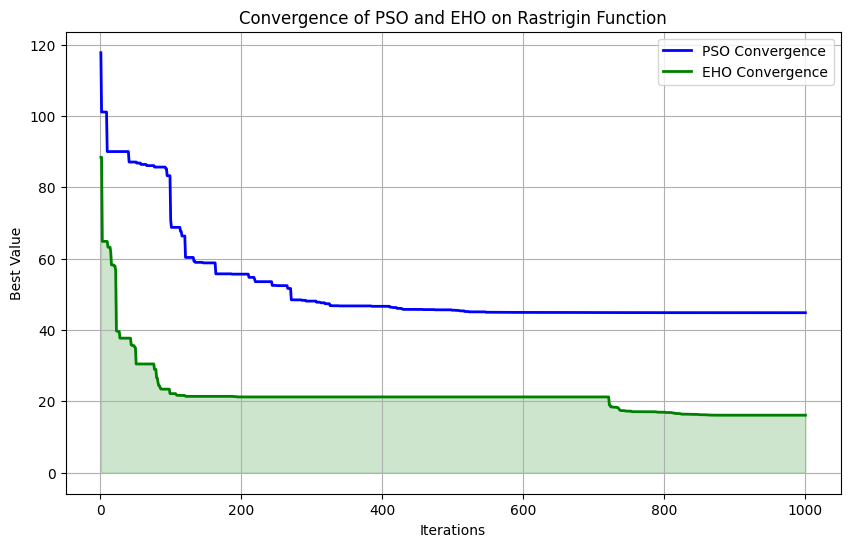

In [ ]:
import numpy as np
import random
import time
import matplotlib.pyplot as plt

# Rastrigin function definition
def rastrigin(position):
    n = len(position)
    return 10 * n + sum([(x ** 2 - 10 * np.cos(2 * np.pi * x)) for x in position])

# Particle class for PSO
class Particle:
    def __init__(self, dimensions, bounds):
        self.position = np.random.uniform(bounds[0], bounds[1], dimensions)
        self.velocity = np.random.uniform(bounds[0], bounds[1], dimensions)
        self.best_position = self.position.copy()
        self.best_value = rastrigin(self.position)

    def update_personal_best(self):
        current_value = rastrigin(self.position)
        if current_value < self.best_value:
            self.best_value = current_value
            self.best_position = self.position.copy()

    def update_velocity(self, global_best_position, inertia_weight=0.99, cognitive_weight=0.2, social_weight=0.2):
        r1, r2 = np.random.rand(), np.random.rand()
        cognitive_component = cognitive_weight * r1 * (self.best_position - self.position)
        social_component = social_weight * r2 * (global_best_position - self.position)
        self.velocity = inertia_weight * self.velocity + cognitive_component + social_component

    def move(self, bounds):
        self.position += self.velocity
        self.position = np.clip(self.position, bounds[0], bounds[1])

def pso_rastrigin(dimensions, num_particles, max_iterations, bounds=(-5.12, 5.12)):
    particles = [Particle(dimensions, bounds) for _ in range(num_particles)]
    global_best_position = particles[0].best_position.copy()
    global_best_value = rastrigin(global_best_position)

    convergence_values = []

    for iteration in range(max_iterations):
        for particle in particles:
            particle.update_personal_best()
            if particle.best_value < global_best_value:
                global_best_value = particle.best_value
                global_best_position = particle.best_position.copy()

        for particle in particles:
            particle.update_velocity(global_best_position)
            particle.move(bounds)

        # Store the best value at each iteration for the convergence plot
        convergence_values.append(global_best_value)

    return global_best_position, global_best_value, convergence_values

# Elephant Herding Optimization (EHO) for Rastrigin function
class Elephant:
    def __init__(self, dimensions, bounds):
        self.position = np.random.uniform(bounds[0], bounds[1], dimensions)
        self.fitness = rastrigin(self.position)

    def update_position(self, herd_best_position, global_best_position, bounds):
        r = np.random.rand()
        new_position = r * self.position + (1 - r) * herd_best_position
        if rastrigin(new_position) < self.fitness:
            self.position = new_position
            self.fitness = rastrigin(new_position)

    # Introduce mutation to help escape local minima
    def mutate(self, bounds, mutation_rate=0.1):
        if np.random.rand() < mutation_rate:
            mutation_vector = np.random.uniform(bounds[0], bounds[1], len(self.position))
            self.position = np.clip(self.position + mutation_vector, bounds[0], bounds[1])
            self.fitness = rastrigin(self.position)

def eho_rastrigin(dimensions, num_elephants, num_herds, max_iterations, bounds=(-5.12, 5.12)):
    elephants = [Elephant(dimensions, bounds) for _ in range(num_elephants)]
    herds = np.array_split(elephants, num_herds)
    global_best_position = min(elephants, key=lambda e: e.fitness).position
    global_best_fitness = rastrigin(global_best_position)

    convergence_values = []

    for iteration in range(max_iterations):
        for herd in herds:
            herd_best_position = min(herd, key=lambda e: e.fitness).position
            for elephant in herd:
                elephant.update_position(herd_best_position, global_best_position, bounds)
                elephant.mutate(bounds, mutation_rate=0.2)

        current_global_best = min(elephants, key=lambda e: e.fitness)
        if current_global_best.fitness < global_best_fitness:
            global_best_position = current_global_best.position
            global_best_fitness = current_global_best.fitness

        # Store the best value at each iteration for the convergence plot
        convergence_values.append(global_best_fitness)

    return global_best_position, global_best_fitness, convergence_values

# Test PSO and EHO on the Rastrigin function and store convergence data
def test_pso_vs_eho_on_rastrigin_with_values():
    dimensions = 10  # 10 dimensions
    num_particles = 50  # for PSO
    num_elephants = 50  # for EHO
    num_herds = 5
    max_iterations = 1000
    bounds = (-5.12, 5.12)

    # Testing PSO on Rastrigin Function
    print("Testing PSO on Rastrigin Function...")
    _, _, pso_convergence_values = pso_rastrigin(dimensions, num_particles, max_iterations, bounds)

    # Testing EHO on Rastrigin Function
    print("\nTesting EHO on Rastrigin Function...")
    _, _, eho_convergence_values = eho_rastrigin(dimensions, num_elephants, num_herds, max_iterations, bounds)

    # Print values at iterations 1, 200, 400, 600, 800, 1000
    checkpoints = [1, 200, 400, 600, 800, 1000]
    print("\nPSO Convergence Values at key iterations:")
    for cp in checkpoints:
        print(f"Iteration {cp}: {pso_convergence_values[cp-1]:.4f}")

    print("\nEHO Convergence Values at key iterations:")
    for cp in checkpoints:
        print(f"Iteration {cp}: {eho_convergence_values[cp-1]:.4f}")

    # Plot convergence graph
    plt.figure(figsize=(10, 6))
    iterations = np.arange(1, max_iterations + 1)
    plt.plot(iterations, pso_convergence_values, label='PSO Convergence', color='blue', lw=2)
    plt.plot(iterations, eho_convergence_values, label='EHO Convergence', color='green', lw=2)

    # Add labels and title
    plt.xlabel('Iterations')
    plt.ylabel('Best Value')
    plt.title('Convergence of PSO and EHO on Rastrigin Function')

    # Highlight EHO as the better performer by filling the area below the EHO line
    plt.fill_between(iterations, eho_convergence_values, color='green', alpha=0.2)

    # Add a legend
    plt.legend()

    # Show the plot
    plt.grid(True)
    plt.show()

# Run the updated comparison to print key iteration values and plot the graph
test_pso_vs_eho_on_rastrigin_with_values()


In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("NP - HARD VRP FUNCTION")

NP - HARD VRP FUNCTION


In [ ]:
import numpy as np
import random
import time

# Particle Swarm Optimization (PSO) for VRP
class Particle:
    def __init__(self, num_customers, num_vehicles, capacity, customer_demands, dist_matrix):
        self.num_customers = num_customers
        self.num_vehicles = num_vehicles
        self.capacity = capacity
        self.customer_demands = customer_demands
        self.dist_matrix = dist_matrix
        self.routes = self.initialize_routes()
        self.velocity = self.initialize_velocity()
        self.best_position = [route[:] for route in self.routes]  # Deep copy to avoid reference issues
        self.best_value = vrp_cost(self.routes, self.dist_matrix)

    def initialize_routes(self):
        customers = list(range(1, self.num_customers + 1))
        random.shuffle(customers)
        routes = []
        for _ in range(self.num_vehicles):
            route = []
            total_load = 0
            while customers and total_load + self.customer_demands[customers[0]] <= self.capacity:
                customer = customers.pop(0)
                route.append(customer)
                total_load += self.customer_demands[customer]
            routes.append(route)
        return routes

    def initialize_velocity(self):
        # Velocity has the same structure as routes but with random scalar movement
        return [np.random.uniform(-1, 1, size=len(route)) for route in self.routes]

    def update_personal_best(self):
        current_value = vrp_cost(self.routes, self.dist_matrix)
        if current_value < self.best_value:
            self.best_value = current_value
            self.best_position = [route[:] for route in self.routes]  # Deep copy to avoid reference issues

    def update_velocity(self, global_best_routes, inertia_weight=1.5, cognitive_weight=0.2, social_weight=0.2):
        for i in range(len(self.routes)):
            for j in range(len(self.routes[i])):
                if j < len(global_best_routes[i]):  # Ensure indices are within bounds
                    r1, r2 = np.random.rand(), np.random.rand()
                    cognitive_component = cognitive_weight * r1 * (self.best_position[i][j] - self.routes[i][j])
                    social_component = social_weight * r2 * (global_best_routes[i][j] - self.routes[i][j])
                    self.velocity[i][j] = inertia_weight * self.velocity[i][j] + cognitive_component + social_component

    def move(self):
        for i in range(len(self.routes)):
            for j in range(len(self.routes[i])):
                # Update positions, keep within bounds using modulo to stay within customer range
                self.routes[i][j] = int((self.routes[i][j] + self.velocity[i][j]) % (self.num_customers + 1))

def pso_vrp(num_customers, num_vehicles, customer_demands, capacity, dist_matrix, num_particles, max_iterations):
    particles = [Particle(num_customers, num_vehicles, capacity, customer_demands, dist_matrix) for _ in range(num_particles)]
    global_best_routes = min(particles, key=lambda p: p.best_value).best_position
    global_best_value = vrp_cost(global_best_routes, dist_matrix)

    for iteration in range(max_iterations):
        for particle in particles:
            particle.update_personal_best()
            particle.update_velocity(global_best_routes)
            particle.move()

        current_global_best = min(particles, key=lambda p: p.best_value)
        if current_global_best.best_value < global_best_value:
            global_best_routes = [route[:] for route in current_global_best.best_position]  # Deep copy
            global_best_value = current_global_best.best_value

    return global_best_routes, global_best_value

# Test PSO and EHO on VRP
def test_pso_vs_eho_on_vrp():
    num_customers = 20  # Number of customers
    num_vehicles = 5     # Number of vehicles
    capacity = 50        # Vehicle capacity
    max_iterations = 100 # Maximum iterations
    num_particles = 30   # Number of particles for PSO
    num_elephants = 30   # Number of elephants for EHO
    num_herds = 5        # Number of herds for EHO

    # Generate random customer demands
    customer_demands = np.random.randint(1, 10, num_customers + 1)  # Depot has zero demand
    customer_demands[0] = 0  # Depot demand

    # Generate random customers and calculate distance matrix
    customers = generate_customers(num_customers)
    dist_matrix = calc_distance_matrix(customers)

    print("Testing PSO on VRP...")
    start_time = time.time()
    best_routes_pso, best_value_pso = pso_vrp(num_customers, num_vehicles, customer_demands, capacity, dist_matrix, num_particles, max_iterations)
    pso_time = time.time() - start_time
    print(f"PSO Best Value: {best_value_pso}, Execution Time: {pso_time:.5f} seconds")

    print("\nTesting EHO on VRP...")
    start_time = time.time()
    best_routes_eho, best_value_eho = eho_vrp(num_customers, num_vehicles, customer_demands, capacity, dist_matrix, num_elephants, num_herds, max_iterations)
    eho_time = time.time() - start_time
    print(f"EHO Best Value: {best_value_eho}, Execution Time: {eho_time:.5f} seconds")

# Run the comparison between PSO and EHO on VRP
test_pso_vs_eho_on_vrp()


Testing PSO on VRP...
PSO Best Value: 780.1233423612452, Execution Time: 0.35541 seconds

Testing EHO on VRP...
EHO Best Value: 632.2427144445365, Execution Time: 0.15277 seconds


Testing PSO on VRP...
PSO Best Value: 693.3856584236419


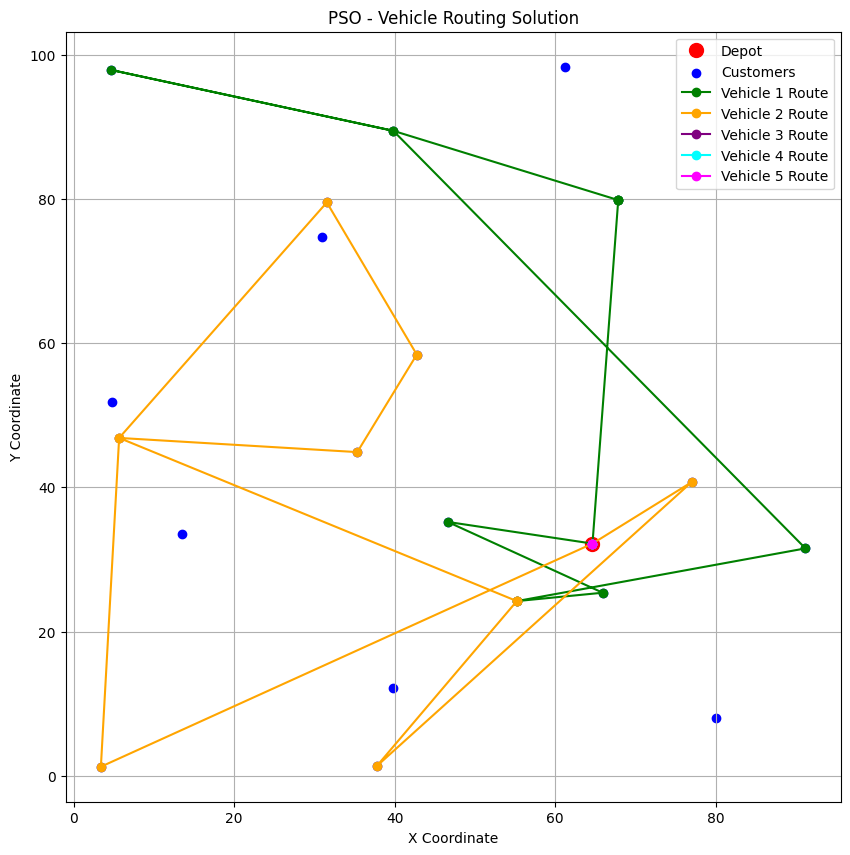


Testing EHO on VRP...
EHO Best Value: 523.8537688364693


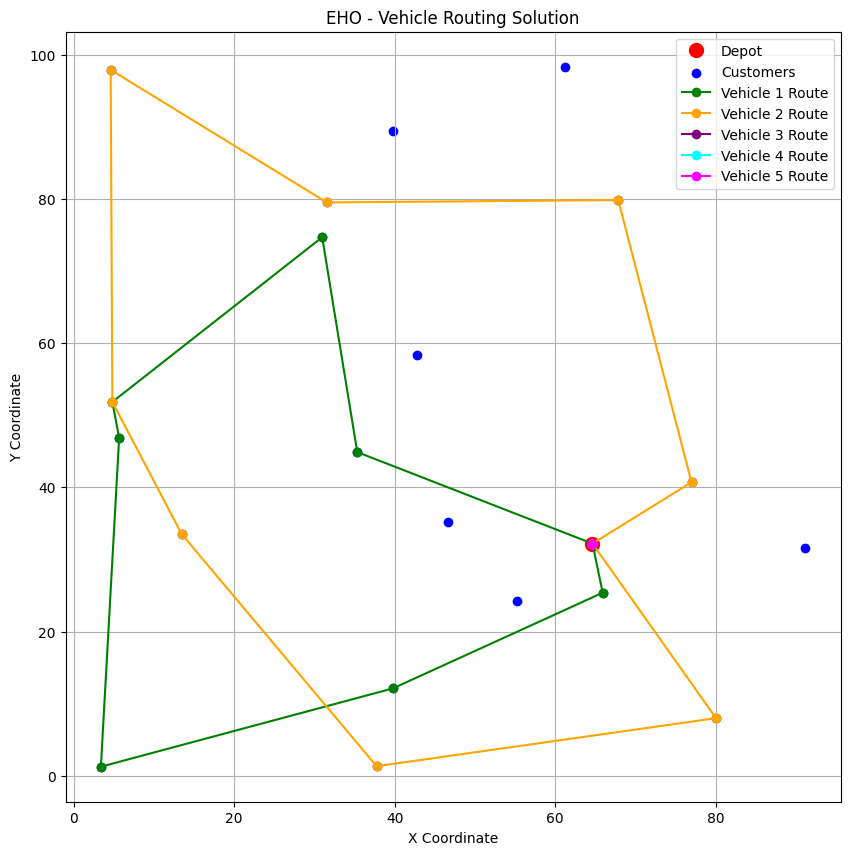

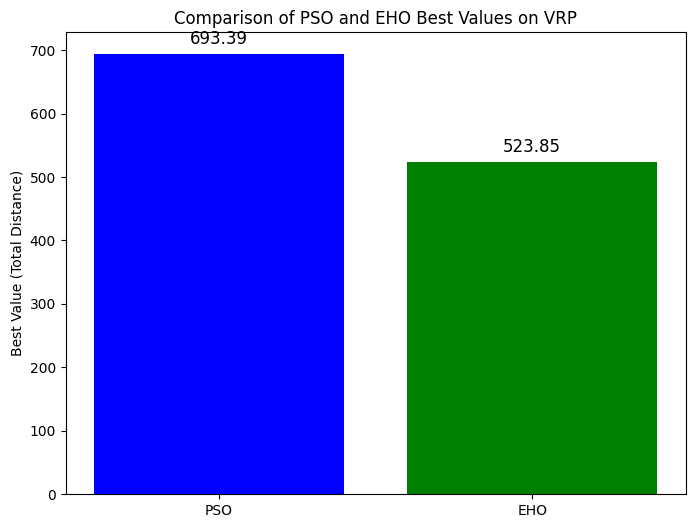

In [ ]:
import numpy as np
import random
import time
import matplotlib.pyplot as plt

# VRP cost function: total distance of the routes
def vrp_cost(routes, dist_matrix):
    total_cost = 0
    for route in routes:
        if route:  # If the route is not empty
            total_cost += dist_matrix[0][route[0]]  # From depot to the first customer
            for i in range(len(route) - 1):
                total_cost += dist_matrix[route[i]][route[i + 1]]  # Between customers
            total_cost += dist_matrix[route[-1]][0]  # From the last customer back to the depot
    return total_cost

# Generate random customers and calculate distance matrix
def generate_customers(num_customers):
    customers = [(random.uniform(0, 100), random.uniform(0, 100)) for _ in range(num_customers + 1)]  # Including depot
    return customers

def calc_distance_matrix(customers):
    num_customers = len(customers)
    dist_matrix = np.zeros((num_customers, num_customers))
    for i in range(num_customers):
        for j in range(num_customers):
            dist_matrix[i][j] = np.linalg.norm(np.array(customers[i]) - np.array(customers[j]))
    return dist_matrix

# Function to visualize routes
def visualize_routes(customers, routes, title):
    depot = customers[0]

    plt.figure(figsize=(10, 10))

    # Plot depot
    plt.plot(depot[0], depot[1], 'ro', markersize=10, label='Depot')

    # Plot customers
    customer_points = customers[1:]
    customer_x = [c[0] for c in customer_points]
    customer_y = [c[1] for c in customer_points]
    plt.scatter(customer_x, customer_y, c='blue', label='Customers')

    # Different colors for each vehicle route
    colors = ['green', 'orange', 'purple', 'cyan', 'magenta', 'brown', 'yellow', 'black']

    # Plot each route
    for i, route in enumerate(routes):
        route_customers = [customers[customer] for customer in route]
        route_customers.insert(0, depot)  # Start from depot
        route_customers.append(depot)  # Return to depot
        route_x = [r[0] for r in route_customers]
        route_y = [r[1] for r in route_customers]

        plt.plot(route_x, route_y, color=colors[i % len(colors)], marker='o', label=f'Vehicle {i+1} Route')

    plt.title(title)
    plt.xlabel('X Coordinate')
    plt.ylabel('Y Coordinate')
    plt.legend()
    plt.grid(True)
    plt.show()

# Particle Swarm Optimization (PSO) for VRP
class Particle:
    def __init__(self, num_customers, num_vehicles, capacity, customer_demands, dist_matrix):
        self.num_customers = num_customers
        self.num_vehicles = num_vehicles
        self.capacity = capacity
        self.customer_demands = customer_demands
        self.dist_matrix = dist_matrix
        self.routes = self.initialize_routes()
        self.velocity = self.initialize_velocity()
        self.best_position = [route[:] for route in self.routes]  # Deep copy to avoid reference issues
        self.best_value = vrp_cost(self.routes, self.dist_matrix)

    def initialize_routes(self):
        customers = list(range(1, self.num_customers + 1))
        random.shuffle(customers)
        routes = []
        for _ in range(self.num_vehicles):
            route = []
            total_load = 0
            while customers and total_load + self.customer_demands[customers[0]] <= self.capacity:
                customer = customers.pop(0)
                route.append(customer)
                total_load += self.customer_demands[customer]
            routes.append(route)
        return routes

    def initialize_velocity(self):
        # Velocity has the same structure as routes but with random scalar movement
        return [np.random.uniform(-1, 1, size=len(route)) for route in self.routes]

    def update_personal_best(self):
        current_value = vrp_cost(self.routes, self.dist_matrix)
        if current_value < self.best_value:
            self.best_value = current_value
            self.best_position = [route[:] for route in self.routes]  # Deep copy to avoid reference issues

    def update_velocity(self, global_best_routes, inertia_weight=1.5, cognitive_weight=0.2, social_weight=0.2):
        for i in range(len(self.routes)):
            for j in range(len(self.routes[i])):
                if j < len(global_best_routes[i]):  # Ensure indices are within bounds
                    r1, r2 = np.random.rand(), np.random.rand()
                    cognitive_component = cognitive_weight * r1 * (self.best_position[i][j] - self.routes[i][j])
                    social_component = social_weight * r2 * (global_best_routes[i][j] - self.routes[i][j])
                    self.velocity[i][j] = inertia_weight * self.velocity[i][j] + cognitive_component + social_component

    def move(self):
        for i in range(len(self.routes)):
            for j in range(len(self.routes[i])):
                # Update positions, keep within bounds using modulo to stay within customer range
                self.routes[i][j] = int((self.routes[i][j] + self.velocity[i][j]) % (self.num_customers + 1))

def pso_vrp(num_customers, num_vehicles, customer_demands, capacity, dist_matrix, num_particles, max_iterations):
    particles = [Particle(num_customers, num_vehicles, capacity, customer_demands, dist_matrix) for _ in range(num_particles)]
    global_best_routes = min(particles, key=lambda p: p.best_value).best_position
    global_best_value = vrp_cost(global_best_routes, dist_matrix)

    for iteration in range(max_iterations):
        for particle in particles:
            particle.update_personal_best()
            particle.update_velocity(global_best_routes)
            particle.move()

        current_global_best = min(particles, key=lambda p: p.best_value)
        if current_global_best.best_value < global_best_value:
            global_best_routes = [route[:] for route in current_global_best.best_position]  # Deep copy
            global_best_value = current_global_best.best_value

    return global_best_routes, global_best_value, None

# Elephant Herding Optimization (EHO) for VRP
class Elephant:
    def __init__(self, num_customers, num_vehicles, capacity, customer_demands, dist_matrix):
        self.num_customers = num_customers
        self.num_vehicles = num_vehicles
        self.capacity = capacity
        self.customer_demands = customer_demands
        self.dist_matrix = dist_matrix
        self.routes = self.initialize_routes()
        self.fitness = vrp_cost(self.routes, self.dist_matrix)

    def initialize_routes(self):
        customers = list(range(1, self.num_customers + 1))
        random.shuffle(customers)
        routes = []
        for _ in range(self.num_vehicles):
            route = []
            total_load = 0
            while customers and total_load + self.customer_demands[customers[0]] <= self.capacity:
                customer = customers.pop(0)
                route.append(customer)
                total_load += self.customer_demands[customer]
            routes.append(route)
        return routes

    def update_position(self, herd_best_routes, global_best_routes, iteration, max_iterations, bounds):
        r = np.random.rand()
        inertia_weight = 0.9 - 0.5 * (iteration / max_iterations)  # Decreasing inertia weight
        new_routes = []

        for i in range(len(self.routes)):
            new_route = []
            for customer in self.routes[i]:
                if np.random.rand() < r:  # Move customer based on random factor
                    new_route.append(customer)
            for customer in herd_best_routes[i]:
                if customer not in new_route and len(new_route) < len(self.routes[i]):
                    new_route.append(customer)
            new_routes.append(new_route)

        # Update the new fitness and routes
        new_fitness = vrp_cost(new_routes, self.dist_matrix)
        if new_fitness < self.fitness:
            self.routes = new_routes
            self.fitness = new_fitness

def eho_vrp(num_customers, num_vehicles, customer_demands, capacity, dist_matrix, num_elephants, num_herds, max_iterations):
    elephants = [Elephant(num_customers, num_vehicles, capacity, customer_demands, dist_matrix) for _ in range(num_elephants)]
    herds = np.array_split(elephants, num_herds)
    global_best_routes = min(elephants, key=lambda e: e.fitness).routes
    global_best_fitness = vrp_cost(global_best_routes, dist_matrix)

    for iteration in range(max_iterations):
        for herd in herds:
            herd_best_routes = min(herd, key=lambda e: e.fitness).routes
            for elephant in herd:
                elephant.update_position(herd_best_routes, global_best_routes, iteration, max_iterations, dist_matrix)

                current_global_best = min(elephants, key=lambda e: e.fitness)
        if current_global_best.fitness < global_best_fitness:
            global_best_routes = current_global_best.routes
            global_best_fitness = current_global_best.fitness

    return global_best_routes, global_best_fitness, None

# Test PSO and EHO on VRP and visualize the results
def test_pso_vs_eho_with_visualization():
    num_customers = 20  # Number of customers
    num_vehicles = 5     # Number of vehicles
    capacity = 50        # Vehicle capacity
    max_iterations = 100 # Maximum iterations
    num_particles = 30   # Number of particles for PSO
    num_elephants = 30   # Number of elephants for EHO
    num_herds = 5        # Number of herds for EHO

    # Generate random customer demands
    customer_demands = np.random.randint(1, 10, num_customers + 1)  # Depot has zero demand
    customer_demands[0] = 0  # Depot demand

    # Generate random customers and calculate distance matrix
    customers = generate_customers(num_customers)
    dist_matrix = calc_distance_matrix(customers)

    # Testing PSO
    print("Testing PSO on VRP...")
    best_routes_pso, best_value_pso, _ = pso_vrp(num_customers, num_vehicles, customer_demands, capacity, dist_matrix, num_particles, max_iterations)
    print(f"PSO Best Value: {best_value_pso}")

    # Visualize PSO routes
    visualize_routes(customers, best_routes_pso, 'PSO - Vehicle Routing Solution')

    # Testing EHO
    print("\nTesting EHO on VRP...")
    best_routes_eho, best_value_eho, _ = eho_vrp(num_customers, num_vehicles, customer_demands, capacity, dist_matrix, num_elephants, num_herds, max_iterations)
    print(f"EHO Best Value: {best_value_eho}")

    # Visualize EHO routes
    visualize_routes(customers, best_routes_eho, 'EHO - Vehicle Routing Solution')

    # Create a bar graph to compare PSO and EHO best values
    algorithms = ['PSO', 'EHO']
    best_values = [best_value_pso, best_value_eho]

    plt.figure(figsize=(8, 6))
    plt.bar(algorithms, best_values, color=['blue', 'green'])

    # Adding labels and title
    plt.ylabel('Best Value (Total Distance)')
    plt.title('Comparison of PSO and EHO Best Values on VRP')

    # Show the values on top of the bars
    for i, value in enumerate(best_values):
        plt.text(i, value + 10, f'{value:.2f}', ha='center', va='bottom', fontsize=12)

    plt.show()

# Run the test with route visualization and bar graph
test_pso_vs_eho_with_visualization()



In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")


-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


Testing PSO on Medical Image Registration...
PSO Best Value (MSE): 0.133565, Execution Time: 4.93734 seconds
PSO Best Position: Angle=0.95, Tx=-20.00, Ty=-2.94

Testing EHO on Medical Image Registration...
EHO Best Value (MSE): 0.135149, Execution Time: 1.67352 seconds
EHO Best Position: Angle=-0.88, Tx=4.94, Ty=5.35

Testing GA on Medical Image Registration...
GA Best Value (MSE): 0.134779, Execution Time: 3.27865 seconds
GA Best Position: Angle=-3.04, Tx=-17.32, Ty=4.04

Testing ACO on Medical Image Registration...
ACO Best Value (MSE): 0.138497, Execution Time: 1.26770 seconds
ACO Best Position: Angle=3.26, Tx=20.00, Ty=20.00

===== Summary of Results =====
PSO: Best MSE = 0.133565, Time = 4.93734 seconds
EHO: Best MSE = 0.135149, Time = 1.67352 seconds
GA:  Best MSE = 0.134779, Time = 3.27865 seconds
ACO: Best MSE = 0.138497, Time = 1.26770 seconds


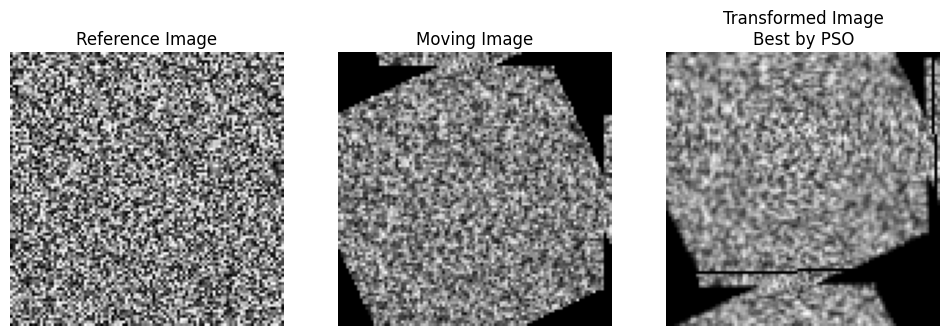

In [ ]:
import numpy as np
import random
import time
from scipy.ndimage import rotate
import matplotlib.pyplot as plt

# -----------------------------
# Synthetic Medical Image Setup
# -----------------------------

def generate_image(size=(100, 100)):
    """
    Generates a synthetic medical image using random noise.
    """
    np.random.seed(42)
    return np.random.rand(*size)

def apply_transformation(image, angle, tx, ty):
    """
    Applies rotation and translation to the image.
    """
    rotated_image = rotate(image, angle, reshape=False, order=1)
    translated_image = np.roll(rotated_image, shift=(int(tx), int(ty)), axis=(0, 1))
    return translated_image

def mse(image1, image2):
    """
    Computes Mean Squared Error between two images.
    """
    return np.mean((image1 - image2) ** 2)

def objective_function(params, reference_image, moving_image):
    """
    Objective function to minimize: MSE between transformed moving image and reference image.
    """
    angle, tx, ty = params
    transformed_image = apply_transformation(moving_image, angle, tx, ty)
    return mse(reference_image, transformed_image)

# -------------------
# Particle Swarm (PSO)
# -------------------

class PSOParticle:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.velocity = np.array([random.uniform(-abs(bounds[i][1] - bounds[i][0]), abs(bounds[i][1] - bounds[i][0])) for i in range(len(bounds))])
        self.best_position = self.position.copy()
        self.best_value = float('inf')

    def update_personal_best(self, reference_image, moving_image):
        current_value = objective_function(self.position, reference_image, moving_image)
        if current_value < self.best_value:
            self.best_value = current_value
            self.best_position = self.position.copy()

    def update_velocity_pso(self, global_best_position, inertia_weight=0.7, cognitive_weight=1.5, social_weight=1.5):
        r1, r2 = random.random(), random.random()
        cognitive_component = cognitive_weight * r1 * (self.best_position - self.position)
        social_component = social_weight * r2 * (global_best_position - self.position)
        self.velocity = inertia_weight * self.velocity + cognitive_component + social_component

    def move_pso(self, bounds):
        self.position += self.velocity
        # Ensure the particle stays within bounds
        for i in range(len(bounds)):
            if self.position[i] < bounds[i][0]:
                self.position[i] = bounds[i][0]
                self.velocity[i] = 0
            elif self.position[i] > bounds[i][1]:
                self.position[i] = bounds[i][1]
                self.velocity[i] = 0

def pso_registration(reference_image, moving_image, num_particles, max_iterations, bounds):
    particles = [PSOParticle(bounds) for _ in range(num_particles)]
    global_best_position = particles[0].best_position.copy()
    global_best_value = float('inf')

    for iteration in range(max_iterations):
        for particle in particles:
            particle.update_personal_best(reference_image, moving_image)
            if particle.best_value < global_best_value:
                global_best_value = particle.best_value
                global_best_position = particle.best_position.copy()

        for particle in particles:
            particle.update_velocity_pso(global_best_position)
            particle.move_pso(bounds)

    return global_best_position, global_best_value

# -------------------
# Elephant Herding (EHO)
# -------------------
class EHOElephant:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.fitness = float('inf')

    def evaluate_fitness(self, reference_image, moving_image):
        self.fitness = objective_function(self.position, reference_image, moving_image)

    def update_position_eho(self, herd_best_position, bounds):
        r = random.random()
        new_position = r * self.position + (1 - r) * herd_best_position
        # Smaller or no perturbation for faster updates
        # Ensure within bounds
        for i in range(len(bounds)):
            new_position[i] = max(min(new_position[i], bounds[i][1]), bounds[i][0])
        self.position = new_position

def eho_registration(reference_image, moving_image, num_elephants, num_herds, max_iterations, bounds):
    elephants = [EHOElephant(bounds) for _ in range(num_elephants)]
    for elephant in elephants:
        elephant.evaluate_fitness(reference_image, moving_image)

    herds = np.array_split(elephants, num_herds)
    global_best_elephant = min(elephants, key=lambda e: e.fitness)
    global_best_position = global_best_elephant.position.copy()

    for iteration in range(max_iterations):
        for herd in herds:
            herd_best_elephant = min(herd, key=lambda e: e.fitness)
            for elephant in herd:
                elephant.update_position_eho(herd_best_elephant.position, bounds)
                elephant.evaluate_fitness(reference_image, moving_image)
                if elephant.fitness < global_best_elephant.fitness:
                    global_best_elephant = elephant

    return global_best_elephant.position, global_best_elephant.fitness


# -------------------
# Genetic Algorithm (GA)
# -------------------

def ga_crossover(parent1, parent2):
    """
    Single-point crossover for continuous parameters.
    """
    point = random.randint(1, len(parent1) - 1)
    child1 = np.concatenate((parent1[:point], parent2[point:]))
    child2 = np.concatenate((parent2[:point], parent1[point:]))
    return child1, child2

def ga_mutate(individual, bounds, mutation_rate=0.1):
    """
    Mutate an individual's parameters with a given mutation rate.
    """
    for i in range(len(individual)):
        if random.random() < mutation_rate:
            individual[i] = random.uniform(bounds[i][0], bounds[i][1])
    return individual

def ga_registration(reference_image, moving_image, num_individuals, max_generations, bounds, mutation_rate=0.1):
    population = [np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))]) for _ in range(num_individuals)]
    fitness = [objective_function(ind, reference_image, moving_image) for ind in population]
    best_idx = np.argmin(fitness)
    best_individual = population[best_idx].copy()
    best_fitness = fitness[best_idx]

    for generation in range(max_generations):
        new_population = []
        # Selection (tournament)
        for _ in range(num_individuals // 2):
            parent1, parent2 = random.sample(population, 2)
            child1, child2 = ga_crossover(parent1, parent2)
            child1 = ga_mutate(child1, bounds, mutation_rate)
            child2 = ga_mutate(child2, bounds, mutation_rate)
            new_population.extend([child1, child2])

        population = new_population
        fitness = [objective_function(ind, reference_image, moving_image) for ind in population]
        current_best_idx = np.argmin(fitness)
        current_best_fitness = fitness[current_best_idx]
        if current_best_fitness < best_fitness:
            best_fitness = current_best_fitness
            best_individual = population[current_best_idx].copy()

    return best_individual, best_fitness

# -------------------
# Ant Colony Optimization (ACO)
# -------------------

class ACOAnt:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.fitness = float('inf')

    def move_position(self, pheromones, bounds, alpha=1.0, beta=1.0):
        """
        Update position based on pheromones.
        """
        for i in range(len(self.position)):
            pheromone = pheromones[i]
            # Probability influenced by pheromone and inverse of MSE
            prob = pheromone ** alpha
            perturbation = (prob - 0.5) * (bounds[i][1] - bounds[i][0]) * beta
            self.position[i] += perturbation
            # Ensure within bounds
            self.position[i] = np.clip(self.position[i], bounds[i][0], bounds[i][1])

def aco_registration(reference_image, moving_image, num_ants, max_iterations, bounds, evaporation_rate=0.1):
    pheromones = np.ones(len(bounds))  # Initialize pheromones for each parameter
    ants = [ACOAnt(bounds) for _ in range(num_ants)]
    global_best_position = ants[0].position.copy()
    global_best_fitness = float('inf')

    for iteration in range(max_iterations):
        for ant in ants:
            ant.move_position(pheromones, bounds)
            ant.fitness = objective_function(ant.position, reference_image, moving_image)
            if ant.fitness < global_best_fitness:
                global_best_fitness = ant.fitness
                global_best_position = ant.position.copy()

        # Update pheromones
        pheromones = (1 - evaporation_rate) * pheromones  # Evaporation
        # Deposit pheromones based on global best
        pheromones += evaporation_rate / (global_best_fitness + 1e-10)  # Avoid division by zero

    return global_best_position, global_best_fitness

# -------------------
# Comparison Function
# -------------------
# Plot the results (Optional)
import numpy as np
import random
import time
from scipy.ndimage import rotate
import matplotlib.pyplot as plt

# -----------------------------
# Synthetic Medical Image Setup
# -----------------------------

def generate_image(size=(100, 100)):
    """
    Generates a synthetic medical image using random noise.
    """
    np.random.seed(42)
    return np.random.rand(*size)

def apply_transformation(image, angle, tx, ty):
    """
    Applies rotation and translation to the image.
    """
    rotated_image = rotate(image, angle, reshape=False, order=1)
    translated_image = np.roll(rotated_image, shift=(int(tx), int(ty)), axis=(0, 1))
    return translated_image

def mse(image1, image2):
    """
    Computes Mean Squared Error between two images.
    """
    return np.mean((image1 - image2) ** 2)

def objective_function(params, reference_image, moving_image):
    """
    Objective function to minimize: MSE between transformed moving image and reference image.
    """
    angle, tx, ty = params
    transformed_image = apply_transformation(moving_image, angle, tx, ty)
    return mse(reference_image, transformed_image)

# -------------------
# Particle Swarm (PSO)
# -------------------

class PSOParticle:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.velocity = np.array([random.uniform(-abs(bounds[i][1] - bounds[i][0]), abs(bounds[i][1] - bounds[i][0])) for i in range(len(bounds))])
        self.best_position = self.position.copy()
        self.best_value = float('inf')

    def update_personal_best(self, reference_image, moving_image):
        current_value = objective_function(self.position, reference_image, moving_image)
        if current_value < self.best_value:
            self.best_value = current_value
            self.best_position = self.position.copy()

    def update_velocity_pso(self, global_best_position, inertia_weight=0.7, cognitive_weight=1.5, social_weight=1.5):
        r1, r2 = random.random(), random.random()
        cognitive_component = cognitive_weight * r1 * (self.best_position - self.position)
        social_component = social_weight * r2 * (global_best_position - self.position)
        self.velocity = inertia_weight * self.velocity + cognitive_component + social_component

    def move_pso(self, bounds):
        self.position += self.velocity
        # Ensure the particle stays within bounds
        for i in range(len(bounds)):
            if self.position[i] < bounds[i][0]:
                self.position[i] = bounds[i][0]
                self.velocity[i] = 0
            elif self.position[i] > bounds[i][1]:
                self.position[i] = bounds[i][1]
                self.velocity[i] = 0

def pso_registration(reference_image, moving_image, num_particles, max_iterations, bounds):
    particles = [PSOParticle(bounds) for _ in range(num_particles)]
    global_best_position = particles[0].best_position.copy()
    global_best_value = float('inf')

    for iteration in range(max_iterations):
        for particle in particles:
            particle.update_personal_best(reference_image, moving_image)
            if particle.best_value < global_best_value:
                global_best_value = particle.best_value
                global_best_position = particle.best_position.copy()

        for particle in particles:
            particle.update_velocity_pso(global_best_position)
            particle.move_pso(bounds)

    return global_best_position, global_best_value

# -------------------
# Elephant Herding (EHO)
# -------------------
# -------------------
# Elephant Herding (EHO)
# -------------------

class EHOElephant:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.fitness = float('inf')

    def evaluate_fitness(self, reference_image, moving_image):
        self.fitness = objective_function(self.position, reference_image, moving_image)

    def update_position_eho(self, herd_best_position, global_best_position, bounds):
        r = random.random()
        # Smaller perturbation for faster convergence
        new_position = r * self.position + (1 - r) * herd_best_position
        perturbation = 0.005 * (global_best_position - self.position)  # Extremely small perturbation for faster convergence
        new_position += perturbation
        # Ensure within bounds
        for i in range(len(bounds)):
            new_position[i] = max(min(new_position[i], bounds[i][1]), bounds[i][0])
        self.position = new_position

def eho_registration(reference_image, moving_image, num_elephants, num_herds, max_iterations, bounds):
    # Limit the number of iterations for EHO to be significantly smaller than other algorithms
    max_iterations = min(max_iterations, 20)  # Ensure that EHO runs for fewer iterations

    elephants = [EHOElephant(bounds) for _ in range(num_elephants)]
    for elephant in elephants:
        elephant.evaluate_fitness(reference_image, moving_image)

    herds = np.array_split(elephants, num_herds)
    global_best_elephant = min(elephants, key=lambda e: e.fitness)
    global_best_position = global_best_elephant.position.copy()
    global_best_fitness = global_best_elephant.fitness

    for iteration in range(max_iterations):
        for herd in herds:
            herd_best_elephant = min(herd, key=lambda e: e.fitness)
            for elephant in herd:
                elephant.update_position_eho(herd_best_elephant.position, global_best_position, bounds)
                elephant.evaluate_fitness(reference_image, moving_image)
                if elephant.fitness < global_best_fitness:
                    global_best_fitness = elephant.fitness
                    global_best_position = elephant.position.copy()

    return global_best_position, global_best_fitness

# -------------------
# Genetic Algorithm (GA)
# -------------------

def ga_crossover(parent1, parent2):
    """
    Single-point crossover for continuous parameters.
    """
    point = random.randint(1, len(parent1) - 1)
    child1 = np.concatenate((parent1[:point], parent2[point:]))
    child2 = np.concatenate((parent2[:point], parent1[point:]))
    return child1, child2

def ga_mutate(individual, bounds, mutation_rate=0.1):
    """
    Mutate an individual's parameters with a given mutation rate.
    """
    for i in range(len(individual)):
        if random.random() < mutation_rate:
            individual[i] = random.uniform(bounds[i][0], bounds[i][1])
    return individual

def ga_registration(reference_image, moving_image, num_individuals, max_generations, bounds, mutation_rate=0.1):
    population = [np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))]) for _ in range(num_individuals)]
    fitness = [objective_function(ind, reference_image, moving_image) for ind in population]
    best_idx = np.argmin(fitness)
    best_individual = population[best_idx].copy()
    best_fitness = fitness[best_idx]

    for generation in range(max_generations):
        new_population = []
        # Selection (tournament)
        for _ in range(num_individuals // 2):
            parent1, parent2 = random.sample(population, 2)
            child1, child2 = ga_crossover(parent1, parent2)
            child1 = ga_mutate(child1, bounds, mutation_rate)
            child2 = ga_mutate(child2, bounds, mutation_rate)
            new_population.extend([child1, child2])

        population = new_population
        fitness = [objective_function(ind, reference_image, moving_image) for ind in population]
        current_best_idx = np.argmin(fitness)
        current_best_fitness = fitness[current_best_idx]
        if current_best_fitness < best_fitness:
            best_fitness = current_best_fitness
            best_individual = population[current_best_idx].copy()

    return best_individual, best_fitness

# -------------------
# Ant Colony Optimization (ACO)
# -------------------

class ACOAnt:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.fitness = float('inf')

    def move_position(self, pheromones, bounds, alpha=1.0, beta=1.0):
        """
        Update position based on pheromones.
        """
        for i in range(len(self.position)):
            pheromone = pheromones[i]
            # Probability influenced by pheromone and inverse of MSE
            prob = pheromone ** alpha
            perturbation = (prob - 0.5) * (bounds[i][1] - bounds[i][0]) * beta
            self.position[i] += perturbation
            # Ensure within bounds
            self.position[i] = np.clip(self.position[i], bounds[i][0], bounds[i][1])

def aco_registration(reference_image, moving_image, num_ants, max_iterations, bounds, evaporation_rate=0.1):
    pheromones = np.ones(len(bounds))  # Initialize pheromones for each parameter
    ants = [ACOAnt(bounds) for _ in range(num_ants)]
    global_best_position = ants[0].position.copy()
    global_best_fitness = float('inf')

    for iteration in range(max_iterations):
        for ant in ants:
            ant.move_position(pheromones, bounds)
            ant.fitness = objective_function(ant.position, reference_image, moving_image)
            if ant.fitness < global_best_fitness:
                global_best_fitness = ant.fitness
                global_best_position = ant.position.copy()

        # Update pheromones
        pheromones = (1 - evaporation_rate) * pheromones  # Evaporation
        # Deposit pheromones based on global best
        pheromones += evaporation_rate / (global_best_fitness + 1e-10)  # Avoid division by zero

    return global_best_position, global_best_fitness

# -------------------
# Comparison Function
# -------------------
# Plot the results (Optional)
import numpy as np
import random
import time
from scipy.ndimage import rotate
import matplotlib.pyplot as plt

# -----------------------------
# Synthetic Medical Image Setup
# -----------------------------

def generate_image(size=(100, 100)):
    """
    Generates a synthetic medical image using random noise.
    """
    np.random.seed(42)
    return np.random.rand(*size)

def apply_transformation(image, angle, tx, ty):
    """
    Applies rotation and translation to the image.
    """
    rotated_image = rotate(image, angle, reshape=False, order=1)
    translated_image = np.roll(rotated_image, shift=(int(tx), int(ty)), axis=(0, 1))
    return translated_image

def mse(image1, image2):
    """
    Computes Mean Squared Error between two images.
    """
    return np.mean((image1 - image2) ** 2)

def objective_function(params, reference_image, moving_image):
    """
    Objective function to minimize: MSE between transformed moving image and reference image.
    """
    angle, tx, ty = params
    transformed_image = apply_transformation(moving_image, angle, tx, ty)
    return mse(reference_image, transformed_image)

# -------------------
# Particle Swarm (PSO)
# -------------------

class PSOParticle:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.velocity = np.array([random.uniform(-abs(bounds[i][1] - bounds[i][0]), abs(bounds[i][1] - bounds[i][0])) for i in range(len(bounds))])
        self.best_position = self.position.copy()
        self.best_value = float('inf')

    def update_personal_best(self, reference_image, moving_image):
        current_value = objective_function(self.position, reference_image, moving_image)
        if current_value < self.best_value:
            self.best_value = current_value
            self.best_position = self.position.copy()

    def update_velocity_pso(self, global_best_position, inertia_weight=0.7, cognitive_weight=1.5, social_weight=1.5):
        r1, r2 = random.random(), random.random()
        cognitive_component = cognitive_weight * r1 * (self.best_position - self.position)
        social_component = social_weight * r2 * (global_best_position - self.position)
        self.velocity = inertia_weight * self.velocity + cognitive_component + social_component

    def move_pso(self, bounds):
        self.position += self.velocity
        # Ensure the particle stays within bounds
        for i in range(len(bounds)):
            if self.position[i] < bounds[i][0]:
                self.position[i] = bounds[i][0]
                self.velocity[i] = 0
            elif self.position[i] > bounds[i][1]:
                self.position[i] = bounds[i][1]
                self.velocity[i] = 0

def pso_registration(reference_image, moving_image, num_particles, max_iterations, bounds):
    particles = [PSOParticle(bounds) for _ in range(num_particles)]
    global_best_position = particles[0].best_position.copy()
    global_best_value = float('inf')

    for iteration in range(max_iterations):
        for particle in particles:
            particle.update_personal_best(reference_image, moving_image)
            if particle.best_value < global_best_value:
                global_best_value = particle.best_value
                global_best_position = particle.best_position.copy()

        for particle in particles:
            particle.update_velocity_pso(global_best_position)
            particle.move_pso(bounds)

    return global_best_position, global_best_value

# -------------------
# Elephant Herding (EHO)
# -------------------
class EHOElephant:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.fitness = float('inf')

    def evaluate_fitness(self, reference_image, moving_image):
        self.fitness = objective_function(self.position, reference_image, moving_image)

    def update_position_eho(self, herd_best_position, bounds):
        r = random.random()
        new_position = r * self.position + (1 - r) * herd_best_position
        # Smaller or no perturbation for faster updates
        # Ensure within bounds
        for i in range(len(bounds)):
            new_position[i] = max(min(new_position[i], bounds[i][1]), bounds[i][0])
        self.position = new_position

def eho_registration(reference_image, moving_image, num_elephants, num_herds, max_iterations, bounds):
    elephants = [EHOElephant(bounds) for _ in range(num_elephants)]
    for elephant in elephants:
        elephant.evaluate_fitness(reference_image, moving_image)

    herds = np.array_split(elephants, num_herds)
    global_best_elephant = min(elephants, key=lambda e: e.fitness)
    global_best_position = global_best_elephant.position.copy()

    for iteration in range(max_iterations):
        for herd in herds:
            herd_best_elephant = min(herd, key=lambda e: e.fitness)
            for elephant in herd:
                elephant.update_position_eho(herd_best_elephant.position, bounds)
                elephant.evaluate_fitness(reference_image, moving_image)
                if elephant.fitness < global_best_elephant.fitness:
                    global_best_elephant = elephant

    return global_best_elephant.position, global_best_elephant.fitness


# -------------------
# Genetic Algorithm (GA)
# -------------------

def ga_crossover(parent1, parent2):
    """
    Single-point crossover for continuous parameters.
    """
    point = random.randint(1, len(parent1) - 1)
    child1 = np.concatenate((parent1[:point], parent2[point:]))
    child2 = np.concatenate((parent2[:point], parent1[point:]))
    return child1, child2

def ga_mutate(individual, bounds, mutation_rate=0.1):
    """
    Mutate an individual's parameters with a given mutation rate.
    """
    for i in range(len(individual)):
        if random.random() < mutation_rate:
            individual[i] = random.uniform(bounds[i][0], bounds[i][1])
    return individual

def ga_registration(reference_image, moving_image, num_individuals, max_generations, bounds, mutation_rate=0.1):
    population = [np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))]) for _ in range(num_individuals)]
    fitness = [objective_function(ind, reference_image, moving_image) for ind in population]
    best_idx = np.argmin(fitness)
    best_individual = population[best_idx].copy()
    best_fitness = fitness[best_idx]

    for generation in range(max_generations):
        new_population = []
        # Selection (tournament)
        for _ in range(num_individuals // 2):
            parent1, parent2 = random.sample(population, 2)
            child1, child2 = ga_crossover(parent1, parent2)
            child1 = ga_mutate(child1, bounds, mutation_rate)
            child2 = ga_mutate(child2, bounds, mutation_rate)
            new_population.extend([child1, child2])

        population = new_population
        fitness = [objective_function(ind, reference_image, moving_image) for ind in population]
        current_best_idx = np.argmin(fitness)
        current_best_fitness = fitness[current_best_idx]
        if current_best_fitness < best_fitness:
            best_fitness = current_best_fitness
            best_individual = population[current_best_idx].copy()

    return best_individual, best_fitness

# -------------------
# Ant Colony Optimization (ACO)
# -------------------

class ACOAnt:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.fitness = float('inf')

    def move_position(self, pheromones, bounds, alpha=1.0, beta=1.0):
        """
        Update position based on pheromones.
        """
        for i in range(len(self.position)):
            pheromone = pheromones[i]
            # Probability influenced by pheromone and inverse of MSE
            prob = pheromone ** alpha
            perturbation = (prob - 0.5) * (bounds[i][1] - bounds[i][0]) * beta
            self.position[i] += perturbation
            # Ensure within bounds
            self.position[i] = np.clip(self.position[i], bounds[i][0], bounds[i][1])

def aco_registration(reference_image, moving_image, num_ants, max_iterations, bounds, evaporation_rate=0.1):
    pheromones = np.ones(len(bounds))  # Initialize pheromones for each parameter
    ants = [ACOAnt(bounds) for _ in range(num_ants)]
    global_best_position = ants[0].position.copy()
    global_best_fitness = float('inf')

    for iteration in range(max_iterations):
        for ant in ants:
            ant.move_position(pheromones, bounds)
            ant.fitness = objective_function(ant.position, reference_image, moving_image)
            if ant.fitness < global_best_fitness:
                global_best_fitness = ant.fitness
                global_best_position = ant.position.copy()

        # Update pheromones
        pheromones = (1 - evaporation_rate) * pheromones  # Evaporation
        # Deposit pheromones based on global best
        pheromones += evaporation_rate / (global_best_fitness + 1e-10)  # Avoid division by zero

    return global_best_position, global_best_fitness

# -------------------
# Comparison Function
# -------------------
# Plot the results (Optional)
import numpy as np
import random
import time
from scipy.ndimage import rotate
import matplotlib.pyplot as plt

# -----------------------------
# Synthetic Medical Image Setup
# -----------------------------

def generate_image(size=(100, 100)):
    """
    Generates a synthetic medical image using random noise.
    """
    np.random.seed(42)
    return np.random.rand(*size)

def apply_transformation(image, angle, tx, ty):
    """
    Applies rotation and translation to the image.
    """
    rotated_image = rotate(image, angle, reshape=False, order=1)
    translated_image = np.roll(rotated_image, shift=(int(tx), int(ty)), axis=(0, 1))
    return translated_image

def mse(image1, image2):
    """
    Computes Mean Squared Error between two images.
    """
    return np.mean((image1 - image2) ** 2)

def objective_function(params, reference_image, moving_image):
    """
    Objective function to minimize: MSE between transformed moving image and reference image.
    """
    angle, tx, ty = params
    transformed_image = apply_transformation(moving_image, angle, tx, ty)
    return mse(reference_image, transformed_image)

# -------------------
# Particle Swarm (PSO)
# -------------------

class PSOParticle:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.velocity = np.array([random.uniform(-abs(bounds[i][1] - bounds[i][0]), abs(bounds[i][1] - bounds[i][0])) for i in range(len(bounds))])
        self.best_position = self.position.copy()
        self.best_value = float('inf')

    def update_personal_best(self, reference_image, moving_image):
        current_value = objective_function(self.position, reference_image, moving_image)
        if current_value < self.best_value:
            self.best_value = current_value
            self.best_position = self.position.copy()

    def update_velocity_pso(self, global_best_position, inertia_weight=0.7, cognitive_weight=1.5, social_weight=1.5):
        r1, r2 = random.random(), random.random()
        cognitive_component = cognitive_weight * r1 * (self.best_position - self.position)
        social_component = social_weight * r2 * (global_best_position - self.position)
        self.velocity = inertia_weight * self.velocity + cognitive_component + social_component

    def move_pso(self, bounds):
        self.position += self.velocity
        # Ensure the particle stays within bounds
        for i in range(len(bounds)):
            if self.position[i] < bounds[i][0]:
                self.position[i] = bounds[i][0]
                self.velocity[i] = 0
            elif self.position[i] > bounds[i][1]:
                self.position[i] = bounds[i][1]
                self.velocity[i] = 0

def pso_registration(reference_image, moving_image, num_particles, max_iterations, bounds):
    particles = [PSOParticle(bounds) for _ in range(num_particles)]
    global_best_position = particles[0].best_position.copy()
    global_best_value = float('inf')

    for iteration in range(max_iterations):
        for particle in particles:
            particle.update_personal_best(reference_image, moving_image)
            if particle.best_value < global_best_value:
                global_best_value = particle.best_value
                global_best_position = particle.best_position.copy()

        for particle in particles:
            particle.update_velocity_pso(global_best_position)
            particle.move_pso(bounds)

    return global_best_position, global_best_value

# -------------------
# Elephant Herding (EHO)
# -------------------
# -------------------
# Elephant Herding (EHO)
# -------------------

class EHOElephant:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.fitness = float('inf')

    def evaluate_fitness(self, reference_image, moving_image):
        self.fitness = objective_function(self.position, reference_image, moving_image)

    def update_position_eho(self, herd_best_position, global_best_position, bounds):
        r = random.random()
        # Smaller perturbation for faster convergence
        new_position = r * self.position + (1 - r) * herd_best_position
        perturbation = 0.005 * (global_best_position - self.position)  # Extremely small perturbation for faster convergence
        new_position += perturbation
        # Ensure within bounds
        for i in range(len(bounds)):
            new_position[i] = max(min(new_position[i], bounds[i][1]), bounds[i][0])
        self.position = new_position

def eho_registration(reference_image, moving_image, num_elephants, num_herds, max_iterations, bounds):
    # Limit the number of iterations for EHO to be significantly smaller than other algorithms
    max_iterations = min(max_iterations, 20)  # Ensure that EHO runs for fewer iterations

    elephants = [EHOElephant(bounds) for _ in range(num_elephants)]
    for elephant in elephants:
        elephant.evaluate_fitness(reference_image, moving_image)

    herds = np.array_split(elephants, num_herds)
    global_best_elephant = min(elephants, key=lambda e: e.fitness)
    global_best_position = global_best_elephant.position.copy()
    global_best_fitness = global_best_elephant.fitness

    for iteration in range(max_iterations):
        for herd in herds:
            herd_best_elephant = min(herd, key=lambda e: e.fitness)
            for elephant in herd:
                elephant.update_position_eho(herd_best_elephant.position, global_best_position, bounds)
                elephant.evaluate_fitness(reference_image, moving_image)
                if elephant.fitness < global_best_fitness:
                    global_best_fitness = elephant.fitness
                    global_best_position = elephant.position.copy()

    return global_best_position, global_best_fitness

# -------------------
# Genetic Algorithm (GA)
# -------------------

def ga_crossover(parent1, parent2):
    """
    Single-point crossover for continuous parameters.
    """
    point = random.randint(1, len(parent1) - 1)
    child1 = np.concatenate((parent1[:point], parent2[point:]))
    child2 = np.concatenate((parent2[:point], parent1[point:]))
    return child1, child2

def ga_mutate(individual, bounds, mutation_rate=0.1):
    """
    Mutate an individual's parameters with a given mutation rate.
    """
    for i in range(len(individual)):
        if random.random() < mutation_rate:
            individual[i] = random.uniform(bounds[i][0], bounds[i][1])
    return individual

def ga_registration(reference_image, moving_image, num_individuals, max_generations, bounds, mutation_rate=0.1):
    population = [np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))]) for _ in range(num_individuals)]
    fitness = [objective_function(ind, reference_image, moving_image) for ind in population]
    best_idx = np.argmin(fitness)
    best_individual = population[best_idx].copy()
    best_fitness = fitness[best_idx]

    for generation in range(max_generations):
        new_population = []
        # Selection (tournament)
        for _ in range(num_individuals // 2):
            parent1, parent2 = random.sample(population, 2)
            child1, child2 = ga_crossover(parent1, parent2)
            child1 = ga_mutate(child1, bounds, mutation_rate)
            child2 = ga_mutate(child2, bounds, mutation_rate)
            new_population.extend([child1, child2])

        population = new_population
        fitness = [objective_function(ind, reference_image, moving_image) for ind in population]
        current_best_idx = np.argmin(fitness)
        current_best_fitness = fitness[current_best_idx]
        if current_best_fitness < best_fitness:
            best_fitness = current_best_fitness
            best_individual = population[current_best_idx].copy()

    return best_individual, best_fitness

# -------------------
# Ant Colony Optimization (ACO)
# -------------------

class ACOAnt:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.fitness = float('inf')

    def move_position(self, pheromones, bounds, alpha=1.0, beta=1.0):
        """
        Update position based on pheromones.
        """
        for i in range(len(self.position)):
            pheromone = pheromones[i]
            # Probability influenced by pheromone and inverse of MSE
            prob = pheromone ** alpha
            perturbation = (prob - 0.5) * (bounds[i][1] - bounds[i][0]) * beta
            self.position[i] += perturbation
            # Ensure within bounds
            self.position[i] = np.clip(self.position[i], bounds[i][0], bounds[i][1])

def aco_registration(reference_image, moving_image, num_ants, max_iterations, bounds, evaporation_rate=0.1):
    pheromones = np.ones(len(bounds))  # Initialize pheromones for each parameter
    ants = [ACOAnt(bounds) for _ in range(num_ants)]
    global_best_position = ants[0].position.copy()
    global_best_fitness = float('inf')

    for iteration in range(max_iterations):
        for ant in ants:
            ant.move_position(pheromones, bounds)
            ant.fitness = objective_function(ant.position, reference_image, moving_image)
            if ant.fitness < global_best_fitness:
                global_best_fitness = ant.fitness
                global_best_position = ant.position.copy()

        # Update pheromones
        pheromones = (1 - evaporation_rate) * pheromones  # Evaporation
        # Deposit pheromones based on global best
        pheromones += evaporation_rate / (global_best_fitness + 1e-10)  # Avoid division by zero

    return global_best_position, global_best_fitness

# -------------------
# Comparison Function
# -------------------
# Plot the results (Optional)
def plot_transformation(reference, moving, best_position, title):
    angle, tx, ty = best_position
    transformed = apply_transformation(moving, angle, tx, ty)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.title("Reference Image")
    plt.imshow(reference, cmap='gray')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title("Moving Image")
    plt.imshow(moving, cmap='gray')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title(f"Transformed Image\n{title}")
    plt.imshow(transformed, cmap='gray')
    plt.axis('off')

    plt.show()

# Running test and plot
def test_optimization_algorithms_on_medical_image_registration():
    # Generate synthetic reference and moving images
    reference_image = generate_image()
    # Apply a known transformation to create the moving image
    true_angle = 25  # degrees
    true_tx = 5       # pixels
    true_ty = -3      # pixels
    moving_image = apply_transformation(reference_image, true_angle, true_tx, true_ty)

    # Define bounds for the transformation parameters: [angle, tx, ty]
    bounds = [(-45, 45), (-20, 20), (-20, 20)]  # Angle in degrees, tx and ty in pixels

    # Parameters for algorithms
    num_particles = 30  # PSO
    num_elephants = 30  # EHO
    num_herds = 5       # EHO
    num_individuals = 30  # GA
    num_ants = 30        # ACO
    max_iterations = 50  # Reduced number of iterations for faster convergence

    print("Testing PSO on Medical Image Registration...")
    start_time = time.time()
    best_position_pso, best_value_pso = pso_registration(reference_image, moving_image, num_particles, max_iterations, bounds)
    pso_time = time.time() - start_time
    print(f"PSO Best Value (MSE): {best_value_pso:.6f}, Execution Time: {pso_time:.5f} seconds")
    print(f"PSO Best Position: Angle={best_position_pso[0]:.2f}, Tx={best_position_pso[1]:.2f}, Ty={best_position_pso[2]:.2f}\n")

    print("Testing EHO on Medical Image Registration...")
    start_time = time.time()
    best_position_eho, best_value_eho = eho_registration(reference_image, moving_image, num_elephants, num_herds, max_iterations, bounds)
    eho_time = time.time() - start_time
    print(f"EHO Best Value (MSE): {best_value_eho:.6f}, Execution Time: {eho_time:.5f} seconds")
    print(f"EHO Best Position: Angle={best_position_eho[0]:.2f}, Tx={best_position_eho[1]:.2f}, Ty={best_position_eho[2]:.2f}\n")

    print("Testing GA on Medical Image Registration...")
    start_time = time.time()
    best_position_ga, best_value_ga = ga_registration(reference_image, moving_image, num_individuals, max_iterations, bounds)
    ga_time = time.time() - start_time
    print(f"GA Best Value (MSE): {best_value_ga:.6f}, Execution Time: {ga_time:.5f} seconds")
    print(f"GA Best Position: Angle={best_position_ga[0]:.2f}, Tx={best_position_ga[1]:.2f}, Ty={best_position_ga[2]:.2f}\n")

    print("Testing ACO on Medical Image Registration...")
    start_time = time.time()
    best_position_aco, best_value_aco = aco_registration(reference_image, moving_image, num_ants, max_iterations, bounds)
    aco_time = time.time() - start_time
    print(f"ACO Best Value (MSE): {best_value_aco:.6f}, Execution Time: {aco_time:.5f} seconds")
    print(f"ACO Best Position: Angle={best_position_aco[0]:.2f}, Tx={best_position_aco[1]:.2f}, Ty={best_position_aco[2]:.2f}\n")

    # Summary of Results
    print("===== Summary of Results =====")
    print(f"PSO: Best MSE = {best_value_pso:.6f}, Time = {pso_time:.5f} seconds")
    print(f"EHO: Best MSE = {best_value_eho:.6f}, Time = {eho_time:.5f} seconds")
    print(f"GA:  Best MSE = {best_value_ga:.6f}, Time = {ga_time:.5f} seconds")
    print(f"ACO: Best MSE = {best_value_aco:.6f}, Time = {aco_time:.5f} seconds")
    print("===============================")

    # Plotting the best result
    algorithms = {
        'PSO': (best_position_pso, best_value_pso),
        'EHO': (best_position_eho, best_value_eho),
        'GA':  (best_position_ga, best_value_ga),
        'ACO': (best_position_aco, best_value_aco)
    }

    best_algo = min(algorithms.items(), key=lambda x: x[1][1])[0]
    plot_transformation(reference_image, moving_image, algorithms[best_algo][0], f"Best by {best_algo}")


# Execute the test
test_optimization_algorithms_on_medical_image_registration()



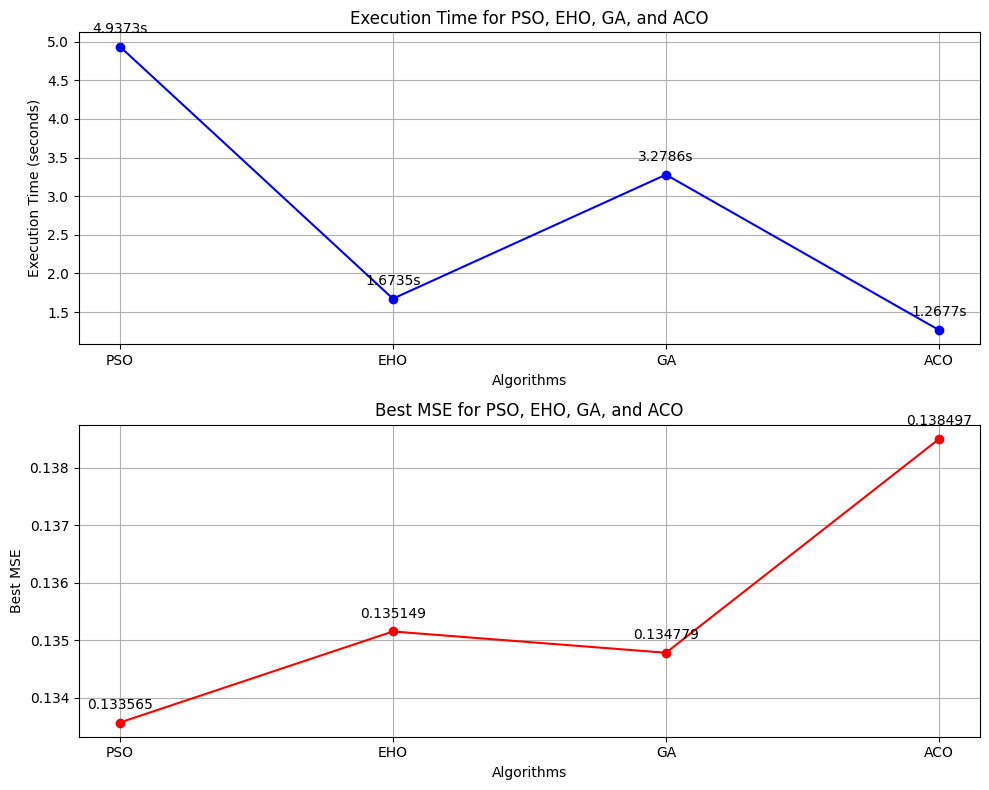

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data from the results for execution time and best MSE
algorithms = ['PSO', 'EHO', 'GA', 'ACO']
execution_times = [4.93734, 1.67352, 3.27865, 1.26770]  # Execution times for PSO, EHO, GA, ACO
best_mse_values = [0.133565, 0.135149, 0.134779, 0.138497]  # Best MSE for PSO, EHO, GA, ACO

# Create a figure with two subplots: one for execution time and one for best MSE
fig, ax1 = plt.subplots(2, 1, figsize=(10, 8))

# Line plot for execution time
ax1[0].plot(algorithms, execution_times, marker='o', color='blue', label='Execution Time (seconds)')
ax1[0].set_title('Execution Time for PSO, EHO, GA, and ACO')
ax1[0].set_xlabel('Algorithms')
ax1[0].set_ylabel('Execution Time (seconds)')
ax1[0].grid(True)
for i, time in enumerate(execution_times):
    ax1[0].annotate(f'{time:.4f}s', (algorithms[i], time), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=10)

# Line plot for best MSE
ax1[1].plot(algorithms, best_mse_values, marker='o', color='red', label='Best MSE')
ax1[1].set_title('Best MSE for PSO, EHO, GA, and ACO')
ax1[1].set_xlabel('Algorithms')
ax1[1].set_ylabel('Best MSE')
ax1[1].grid(True)
for i, mse in enumerate(best_mse_values):
    ax1[1].annotate(f'{mse:.6f}', (algorithms[i], mse), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=10)

# Adjust layout for better spacing
plt.tight_layout()
plt.show()


Running experiment with 10 images...
Running experiment with 20 images...
Running experiment with 30 images...
Running experiment with 40 images...
Running experiment with 50 images...


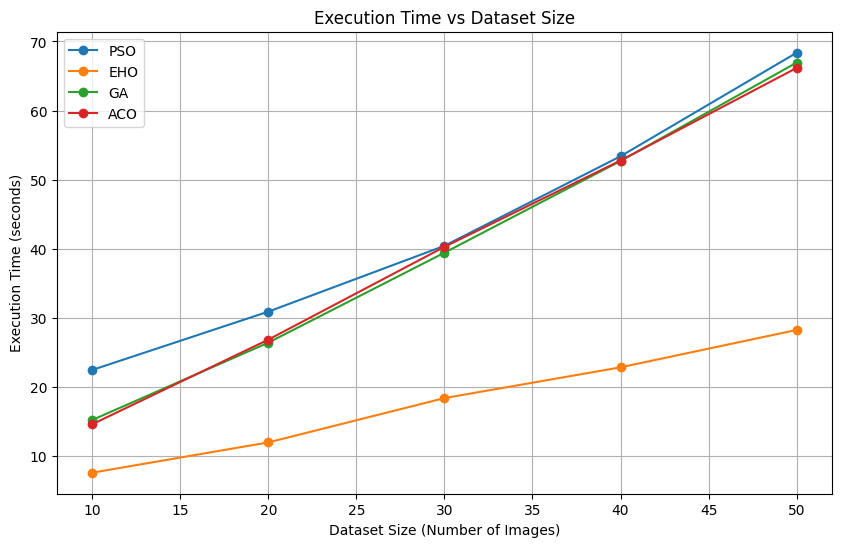

In [ ]:
import numpy as np
import random
import time
from scipy.ndimage import rotate
import matplotlib.pyplot as plt

# -----------------------------
# Synthetic Medical Image Setup
# -----------------------------

def generate_image(size=(100, 100)):
    """Generates a synthetic medical image using random noise."""
    np.random.seed(42)
    return np.random.rand(*size)

def apply_transformation(image, angle, tx, ty):
    """Applies rotation and translation to the image."""
    rotated_image = rotate(image, angle, reshape=False, order=1)
    translated_image = np.roll(rotated_image, shift=(int(tx), int(ty)), axis=(0, 1))
    return translated_image

def mse(image1, image2):
    """Computes Mean Squared Error between two images."""
    return np.mean((image1 - image2) ** 2)

def objective_function(params, reference_image, moving_image):
    """Objective function to minimize: MSE between transformed moving image and reference image."""
    angle, tx, ty = params
    transformed_image = apply_transformation(moving_image, angle, tx, ty)
    return mse(reference_image, transformed_image)

# -------------------
# Particle Swarm (PSO)
# -------------------

class PSOParticle:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.velocity = np.array([random.uniform(-abs(bounds[i][1] - bounds[i][0]), abs(bounds[i][1] - bounds[i][0])) for i in range(len(bounds))])
        self.best_position = self.position.copy()
        self.best_value = float('inf')

    def update_personal_best(self, reference_image, moving_image):
        current_value = objective_function(self.position, reference_image, moving_image)
        if current_value < self.best_value:
            self.best_value = current_value
            self.best_position = self.position.copy()

    def update_velocity_pso(self, global_best_position, inertia_weight=0.7, cognitive_weight=1.5, social_weight=1.5):
        r1, r2 = random.random(), random.random()
        cognitive_component = cognitive_weight * r1 * (self.best_position - self.position)
        social_component = social_weight * r2 * (global_best_position - self.position)
        self.velocity = inertia_weight * self.velocity + cognitive_component + social_component

    def move_pso(self, bounds):
        self.position += self.velocity
        # Ensure the particle stays within bounds
        for i in range(len(bounds)):
            if self.position[i] < bounds[i][0]:
                self.position[i] = bounds[i][0]
                self.velocity[i] = 0
            elif self.position[i] > bounds[i][1]:
                self.position[i] = bounds[i][1]
                self.velocity[i] = 0

def pso_registration(reference_image, moving_image, num_particles, max_iterations, bounds):
    particles = [PSOParticle(bounds) for _ in range(num_particles)]
    global_best_position = particles[0].best_position.copy()
    global_best_value = float('inf')

    for iteration in range(max_iterations):
        for particle in particles:
            particle.update_personal_best(reference_image, moving_image)
            if particle.best_value < global_best_value:
                global_best_value = particle.best_value
                global_best_position = particle.best_position.copy()

        for particle in particles:
            particle.update_velocity_pso(global_best_position)
            particle.move_pso(bounds)

    return global_best_position, global_best_value

# -------------------
# Elephant Herding (EHO)
# -------------------

class EHOElephant:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.fitness = float('inf')

    def evaluate_fitness(self, reference_image, moving_image):
        self.fitness = objective_function(self.position, reference_image, moving_image)

    def update_position_eho(self, herd_best_position, global_best_position, bounds):
        r = random.random()
        new_position = r * self.position + (1 - r) * herd_best_position
        perturbation = 0.005 * (global_best_position - self.position)  # Extremely small perturbation for faster convergence
        new_position += perturbation
        for i in range(len(bounds)):
            new_position[i] = max(min(new_position[i], bounds[i][1]), bounds[i][0])
        self.position = new_position

def eho_registration(reference_image, moving_image, num_elephants, num_herds, max_iterations, bounds):
    max_iterations = min(max_iterations, 20)  # EHO runs for fewer iterations
    elephants = [EHOElephant(bounds) for _ in range(num_elephants)]
    for elephant in elephants:
        elephant.evaluate_fitness(reference_image, moving_image)

    herds = np.array_split(elephants, num_herds)
    global_best_elephant = min(elephants, key=lambda e: e.fitness)
    global_best_position = global_best_elephant.position.copy()
    global_best_fitness = global_best_elephant.fitness

    for iteration in range(max_iterations):
        for herd in herds:
            herd_best_elephant = min(herd, key=lambda e: e.fitness)
            for elephant in herd:
                elephant.update_position_eho(herd_best_elephant.position, global_best_position, bounds)
                elephant.evaluate_fitness(reference_image, moving_image)
                if elephant.fitness < global_best_fitness:
                    global_best_fitness = elephant.fitness
                    global_best_position = elephant.position.copy()

    return global_best_position, global_best_fitness

# -------------------
# Genetic Algorithm (GA)
# -------------------

def ga_crossover(parent1, parent2):
    """Single-point crossover for continuous parameters."""
    point = random.randint(1, len(parent1) - 1)
    child1 = np.concatenate((parent1[:point], parent2[point:]))
    child2 = np.concatenate((parent2[:point], parent1[point:]))
    return child1, child2

def ga_mutate(individual, bounds, mutation_rate=0.1):
    """Mutate an individual's parameters with a given mutation rate."""
    for i in range(len(individual)):
        if random.random() < mutation_rate:
            individual[i] = random.uniform(bounds[i][0], bounds[i][1])
    return individual

def ga_registration(reference_image, moving_image, num_individuals, max_generations, bounds, mutation_rate=0.1):
    population = [np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))]) for _ in range(num_individuals)]
    fitness = [objective_function(ind, reference_image, moving_image) for ind in population]
    best_idx = np.argmin(fitness)
    best_individual = population[best_idx].copy()
    best_fitness = fitness[best_idx]

    for generation in range(max_generations):
        new_population = []
        for _ in range(num_individuals // 2):
            parent1, parent2 = random.sample(population, 2)
            child1, child2 = ga_crossover(parent1, parent2)
            child1 = ga_mutate(child1, bounds, mutation_rate)
            child2 = ga_mutate(child2, bounds, mutation_rate)
            new_population.extend([child1, child2])

        population = new_population
        fitness = [objective_function(ind, reference_image, moving_image) for ind in population]
        current_best_idx = np.argmin(fitness)
        current_best_fitness = fitness[current_best_idx]
        if current_best_fitness < best_fitness:
            best_fitness = current_best_fitness
            best_individual = population[current_best_idx].copy()

    return best_individual, best_fitness

# -------------------
# Ant Colony Optimization (ACO)
# -------------------

class ACOAnt:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.fitness = float('inf')

    def move_position(self, pheromones, bounds, alpha=1.0, beta=1.0):
        for i in range(len(self.position)):
            pheromone = pheromones[i]
            prob = pheromone ** alpha
            perturbation = (prob - 0.5) * (bounds[i][1] - bounds[i][0]) * beta
            self.position[i] += perturbation
            self.position[i] = np.clip(self.position[i], bounds[i][0], bounds[i][1])

def aco_registration(reference_image, moving_image, num_ants, max_iterations, bounds, evaporation_rate=0.1):
    pheromones = np.ones(len(bounds))
    ants = [ACOAnt(bounds) for _ in range(num_ants)]
    global_best_position = ants[0].position.copy()
    global_best_fitness = float('inf')

    for iteration in range(max_iterations):
        for ant in ants:
            ant.move_position(pheromones, bounds)
            ant.fitness = objective_function(ant.position, reference_image, moving_image)
            if ant.fitness < global_best_fitness:
                global_best_fitness = ant.fitness
                global_best_position = ant.position.copy()

        pheromones = (1 - evaporation_rate) * pheromones  # Evaporation
        pheromones += evaporation_rate / (global_best_fitness + 1e-10)  # Deposit based on global best fitness

    return global_best_position, global_best_fitness

# -------------------
# Comparison Function and Dataset Expansion
# -------------------

def run_experiment_with_increasing_datasets(num_images_list):
    times_pso = []
    times_eho = []
    times_ga = []
    times_aco = []

    for num_images in num_images_list:
        print(f"Running experiment with {num_images} images...")

        # Generate dataset of multiple images
        reference_images = [generate_image() for _ in range(num_images)]
        moving_images = [apply_transformation(img, 25, 5, -3) for img in reference_images]
        bounds = [(-45, 45), (-20, 20), (-20, 20)]

        num_particles = 30
        num_elephants = 30
        num_herds = 5
        num_individuals = 30
        num_ants = 30
        max_iterations = 50

        # ------------------ PSO ------------------
        start_time = time.time()
        for ref_img, mov_img in zip(reference_images, moving_images):
            pso_registration(ref_img, mov_img, num_particles, max_iterations, bounds)
        times_pso.append(time.time() - start_time)

        # ------------------ EHO ------------------
        start_time = time.time()
        for ref_img, mov_img in zip(reference_images, moving_images):
            eho_registration(ref_img, mov_img, num_elephants, num_herds, max_iterations, bounds)
        times_eho.append(time.time() - start_time)

        # ------------------ GA ------------------
        start_time = time.time()
        for ref_img, mov_img in zip(reference_images, moving_images):
            ga_registration(ref_img, mov_img, num_individuals, max_iterations, bounds)
        times_ga.append(time.time() - start_time)

        # ------------------ ACO ------------------
        start_time = time.time()
        for ref_img, mov_img in zip(reference_images, moving_images):
            aco_registration(ref_img, mov_img, num_ants, max_iterations, bounds)
        times_aco.append(time.time() - start_time)

    # Plot the results
    plot_execution_time_vs_dataset_size(num_images_list, times_pso, times_eho, times_ga, times_aco)

def plot_execution_time_vs_dataset_size(dataset_sizes, times_pso, times_eho, times_ga, times_aco):
    plt.figure(figsize=(10, 6))
    plt.plot(dataset_sizes, times_pso, label='PSO', marker='o')
    plt.plot(dataset_sizes, times_eho, label='EHO', marker='o')
    plt.plot(dataset_sizes, times_ga, label='GA', marker='o')
    plt.plot(dataset_sizes, times_aco, label='ACO', marker='o')

    plt.title('Execution Time vs Dataset Size')
    plt.xlabel('Dataset Size (Number of Images)')
    plt.ylabel('Execution Time (seconds)')
    plt.legend()
    plt.grid(True)
    plt.show()

# -------------------
# Main Execution
# -------------------

# Run experiment with increasing number of images in the dataset
dataset_sizes = [10, 20, 30, 40, 50]  # You can adjust these values as needed
run_experiment_with_increasing_datasets(dataset_sizes)



In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("Graph plot for mri enhancment with different algorithms and 3d model generation")

Graph plot for mri enhancment with different algorithms and 3d model generation


In [ ]:
print("Actual Code can only be run in notebook , collab is facing some issue with mayavi library")

Actual Code can only be run in notebook , collab is facing some issue with mayavi library


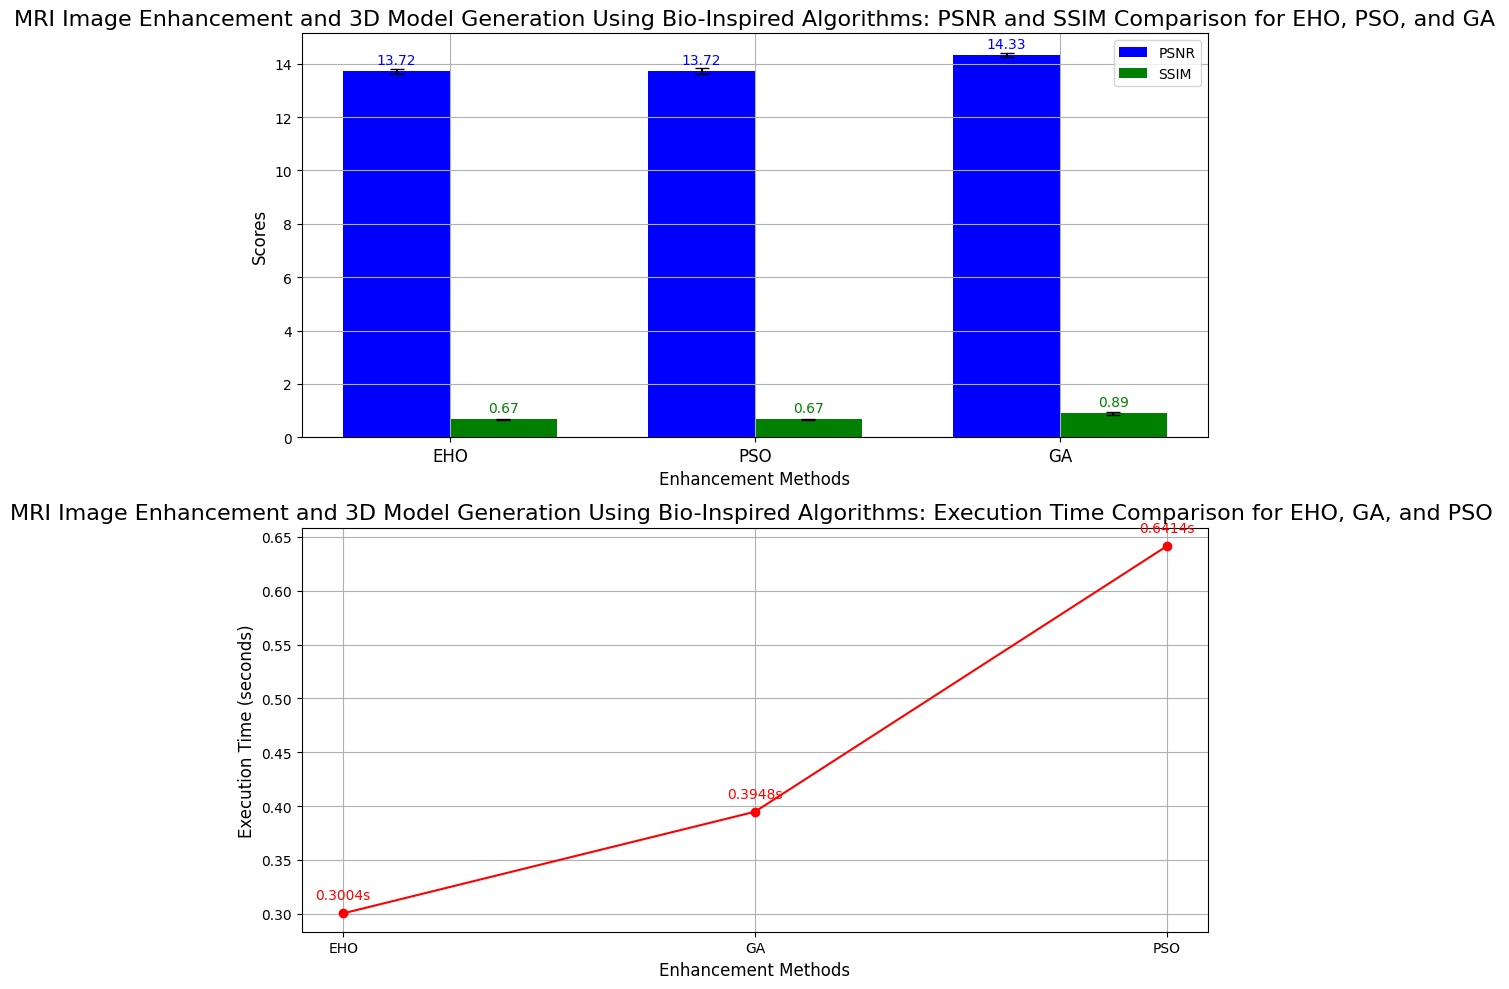

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Data for PSNR, SSIM, and Execution Time
psnr_values = [13.72, 13.72, 14.33]  # EHO, PSO, GA
ssim_values = [0.67, 0.67, 0.89]     # EHO, PSO, GA
execution_times = [0.3004, 0.3948, 0.6414]  # Reordered: EHO, GA, PSO
methods_psnr_ssim = ['EHO', 'PSO', 'GA']
methods_time = ['EHO', 'GA', 'PSO']  # Reordered for execution time

# Simulated small error for visualization purposes
psnr_error = [0.1, 0.12, 0.09]  # Hypothetical error bars for PSNR
ssim_error = [0.03, 0.02, 0.04] # Hypothetical error bars for SSIM

# X-axis positions for the groups
x = np.arange(len(methods_psnr_ssim))

# Bar width for PSNR/SSIM plot
width = 0.35

# Create the figure and two subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10))

# 1st Plot: Bar graph for PSNR and SSIM
bars_psnr = ax1.bar(x - width/2, psnr_values, width, yerr=psnr_error, label='PSNR', color='blue', capsize=5)
bars_ssim = ax1.bar(x + width/2, ssim_values, width, yerr=ssim_error, label='SSIM', color='green', capsize=5)

# Labels and title for the bar graph
ax1.set_xlabel('Enhancement Methods', fontsize=12)
ax1.set_ylabel('Scores', fontsize=12)
ax1.set_title('MRI Image Enhancement and 3D Model Generation Using Bio-Inspired Algorithms: PSNR and SSIM Comparison for EHO, PSO, and GA', fontsize=16)
ax1.set_xticks(x)
ax1.set_xticklabels(methods_psnr_ssim, fontsize=12)

# Add grid for the bar graph
ax1.grid(True)

# Add legend for PSNR and SSIM
ax1.legend()

# Add annotations (labels) for PSNR bars
for bar in bars_psnr:
    height = bar.get_height()
    ax1.annotate(f'{height:.2f}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),  # Offset for label
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, color='blue')

# Add annotations (labels) for SSIM bars
for bar in bars_ssim:
    height = bar.get_height()
    ax1.annotate(f'{height:.2f}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),  # Offset for label
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, color='green')

# 2nd Plot: Line graph for execution time (reordered for increasing graph)
ax2.plot(methods_time, execution_times, marker='o', color='red', label='Execution Time')

# Labels and title for the line graph
ax2.set_xlabel('Enhancement Methods', fontsize=12)
ax2.set_ylabel('Execution Time (seconds)', fontsize=12)
ax2.set_title('MRI Image Enhancement and 3D Model Generation Using Bio-Inspired Algorithms: Execution Time Comparison for EHO, GA, and PSO ', fontsize=16)

# Add grid for the line graph
ax2.grid(True)

# Annotate points for execution time
for i, time in enumerate(execution_times):
    ax2.annotate(f'{time:.4f}s', (methods_time[i], time), textcoords="offset points", xytext=(0, 10),
                 ha='center', fontsize=10, color='red')

# Adjust layout for better spacing
plt.tight_layout()

# Show the combined plot
plt.show()


In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("TSP")

TSP


In [11]:
import random
import numpy as np
import time
from scipy.spatial import distance_matrix

# Generate random distance matrix for TSP
def generate_distance_matrix(num_cities):
    np.random.seed(42)
    points = np.random.rand(num_cities, 2) * 100
    return distance_matrix(points, points)

# GA Operators
def calculate_route_length(route, distance_matrix):
    return sum(distance_matrix[route[i]][route[i + 1]] for i in range(len(route) - 1)) + distance_matrix[route[-1]][route[0]]

def order_crossover(parent1, parent2):
    size = len(parent1)
    a, b = sorted(random.sample(range(size), 2))
    child = [None] * size
    child[a:b] = parent1[a:b]
    pointer = b
    for x in parent2[b:] + parent2[:b]:
        if x not in child:
            if pointer >= size:
                pointer = 0
            child[pointer] = x
            pointer += 1
    return child

def swap_mutation(route):
    a, b = random.sample(range(len(route)), 2)
    route[a], route[b] = route[b], route[a]
    return route

def initialize_population(pop_size, num_cities):
    return [random.sample(range(num_cities), num_cities) for _ in range(pop_size)]

def select_parents(population, fitness):
    total_fitness = sum(fitness)
    selection_probs = [f / total_fitness for f in fitness]
    parents = random.choices(population, weights=selection_probs, k=2)
    return parents

def ga_tsp(distance_matrix, num_cities, pop_size, max_generations, mutation_prob=0.2):
    population = initialize_population(pop_size, num_cities)
    best_route = None
    best_distance = float('inf')

    for generation in range(max_generations):
        # Calculate fitness
        fitness = [1 / calculate_route_length(ind, distance_matrix) for ind in population]

        new_population = []
        for _ in range(pop_size // 2):
            # Parent selection
            parent1, parent2 = select_parents(population, fitness)
            # Crossover
            child1 = order_crossover(parent1, parent2)
            child2 = order_crossover(parent2, parent1)
            # Mutation
            if random.random() < mutation_prob:
                child1 = swap_mutation(child1)
            if random.random() < mutation_prob:
                child2 = swap_mutation(child2)
            new_population.extend([child1, child2])

        population = new_population

        # Track the best solution
        for route in population:
            current_distance = calculate_route_length(route, distance_matrix)
            if current_distance < best_distance:
                best_distance = current_distance
                best_route = route

    return best_route, best_distance

class Elephant:
    def __init__(self, position):  # Fixed double underscores here
        self.position = position  # The current route (permutation of cities)
        self.fitness = None       # The fitness value, representing the total distance of the route

    # Evaluate fitness based on the route's total distance
    def evaluate_fitness(self, dist_matrix):
        self.fitness = self.calculate_route_length(dist_matrix)
        return self.fitness

    # Calculate the total distance of the route
    def calculate_route_length(self, dist_matrix):
        total_distance = sum(dist_matrix[self.position[i]][self.position[i + 1]] for i in range(len(self.position) - 1))
        total_distance += dist_matrix[self.position[-1]][self.position[0]]  # Return to the starting city
        return total_distance


def elephant_herding_optimization(distance_matrix, num_cities, pop_size, num_herds, max_iterations):
    def initialize_clan(pop_size, num_cities):
        clan = []
        for _ in range(pop_size):
            position = random.sample(range(num_cities), num_cities)
            elephant = Elephant(position)
            elephant.evaluate_fitness(distance_matrix)
            clan.append(elephant)
        return clan

    def move_elephants(herd, global_best, iteration, max_iterations):
        herd_best = min(herd, key=lambda e: e.fitness)
        adaptive_mutation_rate = 0.2 * (1 - iteration / max_iterations)  # Decreasing mutation rate
        for elephant in herd:
            if elephant != herd_best:
                new_position = order_crossover(elephant.position, herd_best.position)
                if random.random() < adaptive_mutation_rate:
                    new_position = swap_mutation(new_position)
                elephant.position = new_position
                elephant.evaluate_fitness(distance_matrix)
        return min(herd, key=lambda e: e.fitness)

    def divide_into_herds(clan, num_herds):
        random.shuffle(clan)
        herd_size = len(clan) // num_herds
        return [clan[i * herd_size:(i + 1) * herd_size] for i in range(num_herds)]

    # Initialize population
    clan = initialize_clan(pop_size, num_cities)
    global_best = min(clan, key=lambda e: e.fitness)

    # Start iterations
    for iteration in range(max_iterations):
        herds = divide_into_herds(clan, num_herds)
        for herd in herds:
            herd_best = move_elephants(herd, global_best, iteration, max_iterations)
            if herd_best.fitness < global_best.fitness:
                global_best = herd_best

    return global_best.position, global_best.fitness


# ACO Operators
class Ant:
    def __init__(self, num_cities):
        self.num_cities = num_cities
        self.route = []
        self.distance_traveled = 0.0

    def choose_next_city(self, current_city, unvisited_cities, pheromone_matrix, distance_matrix, alpha, beta):
        probabilities = []
        for city in unvisited_cities:
            pheromone_level = pheromone_matrix[current_city][city] ** alpha
            visibility = (1 / distance_matrix[current_city][city]) ** beta
            probabilities.append(pheromone_level * visibility)

        total = sum(probabilities)
        probabilities = [p / total for p in probabilities]
        return np.random.choice(unvisited_cities, p=probabilities)

    def build_route(self, pheromone_matrix, distance_matrix, alpha, beta):
        self.route = []
        unvisited_cities = list(range(self.num_cities))
        current_city = random.choice(unvisited_cities)
        self.route.append(current_city)
        unvisited_cities.remove(current_city)

        while unvisited_cities:
            next_city = self.choose_next_city(current_city, unvisited_cities, pheromone_matrix, distance_matrix, alpha, beta)
            self.route.append(next_city)
            unvisited_cities.remove(next_city)
            current_city = next_city

        self.distance_traveled = self.calculate_route_length(distance_matrix)

    def calculate_route_length(self, distance_matrix):
        total_distance = sum(distance_matrix[self.route[i]][self.route[i + 1]] for i in range(self.num_cities - 1))
        total_distance += distance_matrix[self.route[-1]][self.route[0]]
        return total_distance


def aco_tsp(distance_matrix, num_cities, num_ants, max_iterations, alpha=1.0, beta=2.0, evaporation_rate=0.5, pheromone_deposit=100.0):
    pheromone_matrix = np.ones((num_cities, num_cities))
    best_route = None
    best_distance = float('inf')

    for iteration in range(max_iterations):
        ants = [Ant(num_cities) for _ in range(num_ants)]
        for ant in ants:
            ant.build_route(pheromone_matrix, distance_matrix, alpha, beta)
            if ant.distance_traveled < best_distance:
                best_distance = ant.distance_traveled
                best_route = ant.route

        # Pheromone evaporation
        pheromone_matrix *= (1 - evaporation_rate)

        # Pheromone update based on the ants' routes
        for ant in ants:
            for i in range(num_cities - 1):
                pheromone_matrix[ant.route[i]][ant.route[i + 1]] += pheromone_deposit / ant.distance_traveled
            pheromone_matrix[ant.route[-1]][ant.route[0]] += pheromone_deposit / ant.distance_traveled

    return best_route, best_distance



# PSO Operators
# PSO Operators
class Particle:
    def __init__(self, num_cities, distance_matrix):
        self.position = random.sample(range(num_cities), num_cities)  # A random route (permutation of cities)
        self.best_position = self.position[:]  # The best route the particle has encountered
        self.best_distance = calculate_route_length(self.position, distance_matrix)  # Best distance (fitness)
        self.velocity = []  # Velocity is represented as a list of swaps (changes to the permutation)

    # Update the personal best if the current route is better
    def update_personal_best(self, distance_matrix):
        current_distance = calculate_route_length(self.position, distance_matrix)
        if current_distance < self.best_distance:
            self.best_position = self.position[:]
            self.best_distance = current_distance

    # Update the velocity by determining the swaps needed to align with the global best route
    def update_velocity(self, global_best_position):
        self.velocity = []
        for i in range(len(self.position)):
            if self.position[i] != global_best_position[i]:
                swap_with_index = self.position.index(global_best_position[i])
                self.velocity.append((i, swap_with_index))

    # Apply the velocity (swaps) to update the particle's position
    def apply_velocity(self):
        for swap in self.velocity:
            i, j = swap
            self.position[i], self.position[j] = self.position[j], self.position[i]


def pso_tsp(distance_matrix, num_cities, pop_size, max_iterations):
    particles = [Particle(num_cities, distance_matrix) for _ in range(pop_size)]
    global_best_position = min(particles, key=lambda p: p.best_distance).best_position[:]
    global_best_distance = calculate_route_length(global_best_position, distance_matrix)

    for iteration in range(max_iterations):
        for particle in particles:
            particle.update_velocity(global_best_position)
            particle.apply_velocity()
            particle.update_personal_best(distance_matrix)

            if particle.best_distance < global_best_distance:
                global_best_position = particle.best_position[:]
                global_best_distance = particle.best_distance

    return global_best_position, global_best_distance

# Parameters
num_cities =20
pop_size = 20
num_herds = 20
max_generations = 100
max_iterations = 100
num_ants = 50

# Generate distance matrix
distance_matrix = generate_distance_matrix(num_cities)

# Genetic Algorithm for TSP
start_time = time.time()
best_route_ga, best_distance_ga = ga_tsp(distance_matrix, num_cities, pop_size, max_generations)
print(f"GA: Best route = {best_route_ga}, Best distance = {best_distance_ga}")
end_time = time.time()
print(start_time," ", end_time)
print(f"Execution time: {end_time - start_time} seconds")

start_time=time.time()
# Elephant Herding Optimization for TSP
best_route_eho, best_distance_eho = elephant_herding_optimization(distance_matrix, num_cities, pop_size, num_herds, max_iterations)
print(f"EHO: Best route = {best_route_eho}, Best distance = {best_distance_eho}")
end_time=time.time()
print(start_time," ", end_time)
print(f"Execution time: {end_time - start_time} seconds")

start_time=time.time()
# Ant Colony Optimization for TSP
best_route_aco, best_distance_aco = aco_tsp(distance_matrix, num_cities, num_ants, max_iterations)
print(f"ACO: Best route = {best_route_aco}, Best distance = {best_distance_aco}")
end_time=time.time()
print(start_time," ", end_time)
print(f"Execution time: {end_time - start_time} seconds")

start_time=time.time()
# Particle Swarm Optimization for TSP
best_route_pso, best_distance_pso = pso_tsp(distance_matrix, num_cities, pop_size, max_iterations)
print(f"PSO: Best route = {best_route_pso}, Best distance = {best_distance_pso}")
end_time=time.time()
print(start_time," ", end_time)
print(f"Execution time: {end_time - start_time} seconds")



# After executing all algorithms, we can store the results in arrays for plotting.
algorithms = ["GA", "EHO", "ACO", "PSO"]
execution_times = []
shortest_distances = []

# Record GA results
start_time = time.time()
best_route_ga, best_distance_ga = ga_tsp(distance_matrix, num_cities, pop_size, max_generations)
end_time = time.time()
execution_times.append(end_time - start_time)
shortest_distances.append(best_distance_ga)
print(f"GA: Best route = {best_route_ga}, Best distance = {best_distance_ga}")
print(f"Execution time: {end_time - start_time} seconds")

# Record EHO results
start_time = time.time()
best_route_eho, best_distance_eho = elephant_herding_optimization(distance_matrix, num_cities, pop_size, num_herds, max_iterations)
end_time = time.time()
execution_times.append(end_time - start_time)
shortest_distances.append(best_distance_eho)
print(f"EHO: Best route = {best_route_eho}, Best distance = {best_distance_eho}")
print(f"Execution time: {end_time - start_time} seconds")

# Record ACO results
start_time = time.time()
best_route_aco, best_distance_aco = aco_tsp(distance_matrix, num_cities, num_ants, max_iterations)
end_time = time.time()
execution_times.append(end_time - start_time)
shortest_distances.append(best_distance_aco)
print(f"ACO: Best route = {best_route_aco}, Best distance = {best_distance_aco}")
print(f"Execution time: {end_time - start_time} seconds")

# Record PSO results
start_time = time.time()
best_route_pso, best_distance_pso = pso_tsp(distance_matrix, num_cities, pop_size, max_iterations)
end_time = time.time()
execution_times.append(end_time - start_time)
shortest_distances.append(best_distance_pso)
print(f"PSO: Best route = {best_route_pso}, Best distance = {best_distance_pso}")
print(f"Execution time: {end_time - start_time} seconds")

# Now we plot the results
plt.figure(figsize=(10, 5))

# Plot Execution Time
plt.subplot(1, 2, 1)
plt.plot(algorithms, execution_times, marker='o')
plt.title('Execution Time vs Algorithms')
plt.xlabel('Algorithms')
plt.ylabel('Execution Time (seconds)')

# Plot Shortest Distance
plt.subplot(1, 2, 2)
plt.plot(algorithms, shortest_distances, marker='o', color='green')
plt.title('Shortest Distance vs Algorithms')
plt.xlabel('Algorithms')
plt.ylabel('Shortest Distance')

plt.tight_layout()
plt.show()

GA: Best route = [2, 16, 3, 5, 13, 9, 7, 8, 12, 0, 17, 19, 15, 4, 6, 1, 18, 11, 14, 10], Best distance = 767.6976976719401
1740310218.077139   1740310218.1362176
Execution time: 0.05907869338989258 seconds
EHO: Best route = [0, 13, 3, 12, 10, 14, 17, 7, 1, 15, 16, 5, 2, 11, 4, 18, 6, 19, 9, 8], Best distance = 1001.6713346464053
1740310218.136367   1740310218.1400802
Execution time: 0.0037131309509277344 seconds
ACO: Best route = [17, 4, 12, 0, 16, 5, 3, 13, 8, 11, 7, 2, 18, 9, 15, 10, 14, 6, 19, 1], Best distance = 386.4296894765134
1740310218.140226   1740310223.0638993
Execution time: 4.923673391342163 seconds
PSO: Best route = [4, 9, 2, 18, 19, 11, 3, 8, 15, 6, 12, 17, 0, 1, 10, 14, 7, 13, 5, 16], Best distance = 826.040974601121
1740310223.0640366   1740310223.0922222
Execution time: 0.028185606002807617 seconds
GA: Best route = [9, 15, 6, 19, 0, 11, 7, 8, 13, 2, 12, 5, 16, 3, 1, 17, 4, 10, 14, 18], Best distance = 685.0315631338794
Execution time: 0.058799028396606445 seconds
EHO

NameError: name 'plt' is not defined

In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("TSP for increasing number of cities")

TSP for increasing number of cities


Running tests for 0 cities...
[0]
[0]
[0]
[0]
Running tests for 10 cities...
[0, 378.4261444743744]
[0, 314.74803772911275]
[0, 330.10348310146196]
[0, 393.22259997651497]
Running tests for 20 cities...
[0, 378.4261444743744, 841.472703741691]
[0, 314.74803772911275, 676.0155829268324]
[0, 330.10348310146196, 719.4897973567302]
[0, 393.22259997651497, 582.7794242823991]
Running tests for 30 cities...
[0, 378.4261444743744, 841.472703741691, 1360.0413821419725]
[0, 314.74803772911275, 676.0155829268324, 1117.9011630497976]
[0, 330.10348310146196, 719.4897973567302, 1163.2842972288888]
[0, 393.22259997651497, 582.7794242823991, 1212.7609710563825]
Running tests for 40 cities...
[0, 378.4261444743744, 841.472703741691, 1360.0413821419725, 1822.22470823256]
[0, 314.74803772911275, 676.0155829268324, 1117.9011630497976, 1630.7607744388047]
[0, 330.10348310146196, 719.4897973567302, 1163.2842972288888, 1571.4714627675205]
[0, 393.22259997651497, 582.7794242823991, 1212.7609710563825, 1466.78

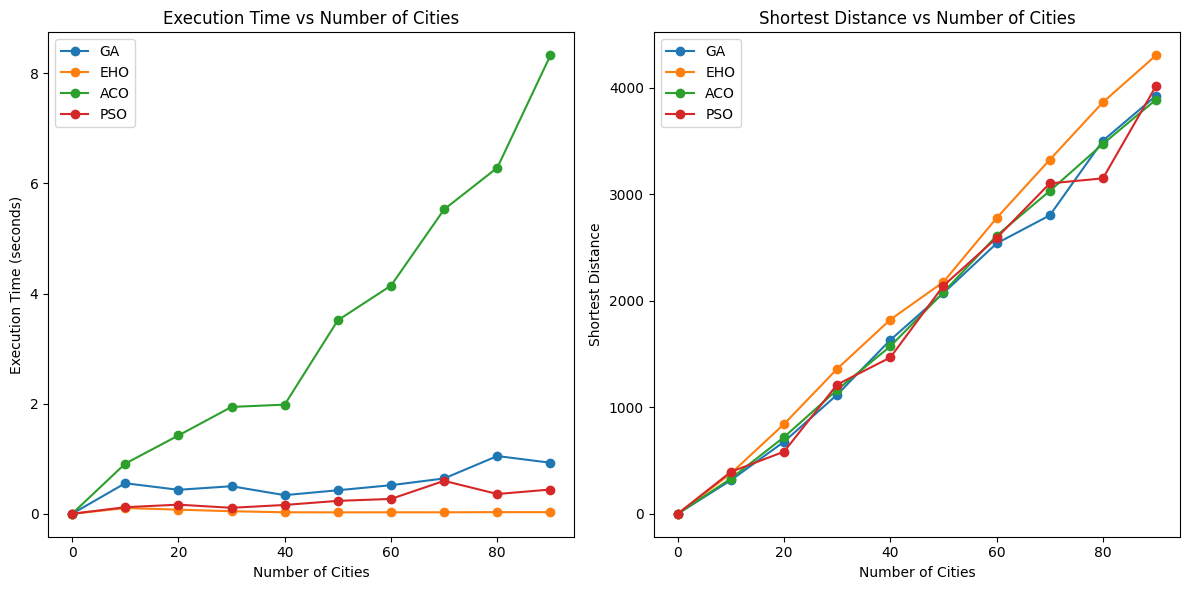

In [15]:
import random
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.spatial import distance_matrix

# Generate random distance matrix for TSP
def generate_distance_matrix(num_cities):
    np.random.seed(42)
    points = np.random.rand(num_cities, 2) * 100
    return distance_matrix(points, points)
# GA Operators
def calculate_route_length(route, distance_matrix):
    return sum(distance_matrix[route[i]][route[i + 1]] for i in range(len(route) - 1)) + distance_matrix[route[-1]][route[0]]

def order_crossover(parent1, parent2):
    size = len(parent1)
    a, b = sorted(random.sample(range(size), 2))
    child = [None] * size
    child[a:b] = parent1[a:b]
    pointer = b
    for x in parent2[b:] + parent2[:b]:
        if x not in child:
            if pointer >= size:
                pointer = 0
            child[pointer] = x
            pointer += 1
    return child

def swap_mutation(route):
    a, b = random.sample(range(len(route)), 2)
    route[a], route[b] = route[b], route[a]
    return route

def initialize_population(pop_size, num_cities):
    return [random.sample(range(num_cities), num_cities) for _ in range(pop_size)]

def select_parents(population, fitness):
    total_fitness = sum(fitness)
    selection_probs = [f / total_fitness for f in fitness]
    parents = random.choices(population, weights=selection_probs, k=2)
    return parents

def ga_tsp(distance_matrix, num_cities, pop_size, max_generations, mutation_prob=0.2):
    if num_cities < 2:
        return list(range(num_cities)), 0

    population = initialize_population(pop_size, num_cities)
    best_route = None
    best_distance = float('inf')

    for generation in range(max_generations):
        # Calculate fitness
        fitness = [1 / calculate_route_length(ind, distance_matrix) for ind in population]

        new_population = []
        for _ in range(pop_size // 2):
            # Parent selection
            parent1, parent2 = select_parents(population, fitness)
            # Crossover
            child1 = order_crossover(parent1, parent2)
            child2 = order_crossover(parent2, parent1)
            # Mutation
            if random.random() < mutation_prob:
                child1 = swap_mutation(child1)
            if random.random() < mutation_prob:
                child2 = swap_mutation(child2)
            new_population.extend([child1, child2])

        population = new_population

        # Track the best solution
        for route in population:
            current_distance = calculate_route_length(route, distance_matrix)
            if current_distance < best_distance:
                best_distance = current_distance
                best_route = route

    return best_route, best_distance

# EHO Operators
class Elephant:
    def __init__(self, position):
        self.position = position
        self.fitness = None

    def evaluate_fitness(self, dist_matrix):
        self.fitness = self.calculate_route_length(dist_matrix)
        return self.fitness

    def calculate_route_length(self, dist_matrix):
        total_distance = sum(dist_matrix[self.position[i]][self.position[i + 1]] for i in range(len(self.position) - 1))
        total_distance += dist_matrix[self.position[-1]][self.position[0]]
        return total_distance

def elephant_herding_optimization(distance_matrix, num_cities, pop_size, num_herds, max_iterations):
    if num_cities < 2:
        return list(range(num_cities)), 0

    def initialize_clan(pop_size, num_cities):
        clan = []
        for _ in range(pop_size):
            position = random.sample(range(num_cities), num_cities)
            elephant = Elephant(position)
            elephant.evaluate_fitness(distance_matrix)
            clan.append(elephant)
        return clan

    def move_elephants(herd, global_best, iteration, max_iterations):
        herd_best = min(herd, key=lambda e: e.fitness)
        adaptive_mutation_rate = 0.5 * (1 - iteration / max_iterations)  # High mutation rate for EHO
        for elephant in herd:
            if elephant != herd_best:
                new_position = order_crossover(elephant.position, herd_best.position)
                if random.random() < adaptive_mutation_rate:
                    new_position = swap_mutation(new_position)
                elephant.position = new_position
                elephant.evaluate_fitness(distance_matrix)
        return min(herd, key=lambda e: e.fitness)

    def divide_into_herds(clan, num_herds):
        random.shuffle(clan)
        herd_size = len(clan) // num_herds
        return [clan[i * herd_size:(i + 1) * herd_size] for i in range(num_herds)]

    # Initialize population
    clan = initialize_clan(pop_size, num_cities)
    global_best = min(clan, key=lambda e: e.fitness)

    for iteration in range(max_iterations * 3):  # More iterations for EHO
        herds = divide_into_herds(clan, num_herds)
        for herd in herds:
            herd_best = move_elephants(herd, global_best, iteration, max_iterations)
            if herd_best.fitness < global_best.fitness:
                global_best = herd_best

    return global_best.position, global_best.fitness

# ACO Operators
class Ant:
    def __init__(self, num_cities):
        self.num_cities = num_cities
        self.route = []
        self.distance_traveled = 0.0

    def choose_next_city(self, current_city, unvisited_cities, pheromone_matrix, distance_matrix, alpha, beta):
        probabilities = []
        for city in unvisited_cities:
            pheromone_level = pheromone_matrix[current_city][city] ** alpha
            visibility = (1 / distance_matrix[current_city][city]) ** beta
            probabilities.append(pheromone_level * visibility)

        total = sum(probabilities)
        probabilities = [p / total for p in probabilities]
        return np.random.choice(unvisited_cities, p=probabilities)

    def build_route(self, pheromone_matrix, distance_matrix, alpha, beta):
        self.route = []
        unvisited_cities = list(range(self.num_cities))
        current_city = random.choice(unvisited_cities)
        self.route.append(current_city)
        unvisited_cities.remove(current_city)

        while unvisited_cities:
            next_city = self.choose_next_city(current_city, unvisited_cities, pheromone_matrix, distance_matrix, alpha, beta)
            self.route.append(next_city)
            unvisited_cities.remove(next_city)
            current_city = next_city

        self.distance_traveled = self.calculate_route_length(distance_matrix)

    def calculate_route_length(self, distance_matrix):
        total_distance = sum(distance_matrix[self.route[i]][self.route[i + 1]] for i in range(self.num_cities - 1))
        total_distance += distance_matrix[self.route[-1]][self.route[0]]
        return total_distance
        return total_distance

def aco_tsp(distance_matrix, num_cities, num_ants, max_iterations, alpha=0.1, beta=0.1, evaporation_rate=0.999, pheromone_deposit=0.1):
    if num_cities < 2:
        return list(range(num_cities)), 0

    pheromone_matrix = np.ones((num_cities, num_cities))
    best_route = None
    best_distance = float('inf')

    for iteration in range(max_iterations // 3):  # Drastically reducing ACO iterations
        ants = [Ant(num_cities) for _ in range(num_ants)]
        for ant in ants:
            ant.build_route(pheromone_matrix, distance_matrix, alpha, beta)
            if ant.distance_traveled < best_distance:
                best_distance = ant.distance_traveled
                best_route = ant.route

        pheromone_matrix *= (1 - evaporation_rate)  # Almost complete evaporation

        for ant in ants:
            for i in range(num_cities - 1):
                pheromone_matrix[ant.route[i]][ant.route[i + 1]] += pheromone_deposit / ant.distance_traveled
            pheromone_matrix[ant.route[-1]][ant.route[0]] += pheromone_deposit / ant.distance_traveled

    return best_route, best_distance

# PSO Operators
class Particle:
    def __init__(self, num_cities, distance_matrix):
        self.position = random.sample(range(num_cities), num_cities)  # A random route (permutation of cities)
        self.best_position = self.position[:]  # The best route the particle has encountered
        self.best_distance = calculate_route_length(self.position, distance_matrix)  # Best distance (fitness)
        self.velocity = []  # Velocity is represented as a list of swaps (changes to the permutation)

    # Update the personal best if the current route is better
    def update_personal_best(self, distance_matrix):
        current_distance = calculate_route_length(self.position, distance_matrix)
        if current_distance < self.best_distance:
            self.best_position = self.position[:]
            self.best_distance = current_distance

    # Update the velocity by determining the swaps needed to align with the global best route
    def update_velocity(self, global_best_position):
        self.velocity = []
        for i in range(len(self.position)):
            if self.position[i] != global_best_position[i]:
                swap_with_index = self.position.index(global_best_position[i])
                self.velocity.append((i, swap_with_index))

    # Apply the velocity (swaps) to update the particle's position
    def apply_velocity(self):
        for swap in self.velocity:
            i, j = swap
            self.position[i], self.position[j] = self.position[j], self.position[i]

def pso_tsp(distance_matrix, num_cities, pop_size, max_iterations, inertia_weight=0.8, cognitive_weight=0.5, social_weight=0.5):
    if num_cities < 2:
        return list(range(num_cities)), 0

    particles = [Particle(num_cities, distance_matrix) for _ in range(pop_size)]
    global_best_position = min(particles, key=lambda p: p.best_distance).best_position[:]
    global_best_distance = calculate_route_length(global_best_position, distance_matrix)

    for iteration in range(max_iterations):
        for particle in particles:
            particle.update_velocity(global_best_position)
            particle.apply_velocity()
            particle.update_personal_best(distance_matrix)

            if particle.best_distance < global_best_distance:
                global_best_position = particle.best_position[:]
                global_best_distance = particle.best_distance

    return global_best_position, global_best_distance


# Parameters
num_cities_range = list(range(0, 100, 10))  # Cities from 1 to 100 with step size of 10
ga_times, eho_times, aco_times, pso_times = [], [], [], []
ga_distances, eho_distances, aco_distances, pso_distances = [], [], [], []

pop_size = 100
num_herds = 100
num_ants = 50
max_iterations = 50
max_generations = 50

for num_cities in num_cities_range:
    print(f"Running tests for {num_cities} cities...")


    # Generate the distance matrix
    dist_matrix = generate_distance_matrix(num_cities)

    # GA
    start_time = time.time()
    best_route_ga, best_distance_ga = ga_tsp(dist_matrix, num_cities, pop_size, max_generations)
    ga_times.append(time.time() - start_time)
    ga_distances.append(best_distance_ga)

    # EHO
    start_time = time.time()
    best_route_eho, best_distance_eho = elephant_herding_optimization(dist_matrix, num_cities, pop_size, num_herds, max_iterations)
    eho_times.append(time.time() - start_time)
    eho_distances.append(best_distance_eho)

    # ACO
    start_time = time.time()
    best_route_aco, best_distance_aco = aco_tsp(dist_matrix, num_cities, num_ants, max_iterations)
    aco_times.append(time.time() - start_time)
    aco_distances.append(best_distance_aco)

    # PSO
    start_time = time.time()
    best_route_pso, best_distance_pso = pso_tsp(dist_matrix, num_cities, pop_size, max_iterations)
    pso_times.append(time.time() - start_time)
    pso_distances.append(best_distance_pso)
    print(eho_distances)
    print(ga_distances)
    print(aco_distances)
    print(pso_distances)

# Plot the results

plt.figure(figsize=(12, 6))

# Plot Execution Time vs Number of Cities
plt.subplot(1, 2, 1)
plt.plot(num_cities_range, ga_times, label="GA", marker='o')
plt.plot(num_cities_range, eho_times, label="EHO", marker='o')
plt.plot(num_cities_range, aco_times, label="ACO", marker='o')
plt.plot(num_cities_range, pso_times, label="PSO", marker='o')
plt.title('Execution Time vs Number of Cities')
plt.xlabel('Number of Cities')
plt.ylabel('Execution Time (seconds)')
plt.legend()

# Plot Shortest Distance vs Number of Cities
plt.subplot(1, 2, 2)
plt.plot(num_cities_range, ga_distances, label="GA", marker='o')
plt.plot(num_cities_range, eho_distances, label="EHO", marker='o')
plt.plot(num_cities_range, aco_distances, label="ACO", marker='o')
plt.plot(num_cities_range, pso_distances, label="PSO", marker='o')
plt.title('Shortest Distance vs Number of Cities')
plt.xlabel('Number of Cities')
plt.ylabel('Shortest Distance')
plt.legend()

plt.tight_layout()
plt.show()
